# 📊 Análise Exploratória de Dados Completa (EDA): Padrões de Consumo, Cardápio, Sazonalidade, Clima e Trade-off Falta vs. Sobra
## Suíte de 24 Representações Gráficas para a Dissertação de Mestrado Profissional

* **Instituição de Ensino:** Instituto Federal de São Paulo (IFSP) – Campus Itaquaquecetuba
* **Localização:** Rua Primeiro de Maio, nº 500, Bairro Estação, Itaquaquecetuba - SP
* **Referência Espacial:** ~500 metros da Estação CPTM Linha 12-Safira
* **Base de Dados:** Camada Silver (`dados/silver/silver_fato_diaria.parquet`)
* **Período Coberto:** 2023 a 2026 (1.461 dias analisados)
* **Destino das Figuras:** Pasta `reports/figuras/` em 300 DPI para inserção direta no texto da dissertação.

---
### 🧭 Estrutura da Suíte Gráfica (24 Figuras)
* **Bloco A: Série Temporal e Evolução Longitudinal** (Figuras 01 a 04)
* **Bloco B: Confronto Reserva vs. Consumo Real e Balanço Falta vs. Sobra** (Figuras 05 a 09)
* **Bloco C: Sazonalidades Semanal e Mensal Desdobradas por Ano** (Figuras 10 a 13)
* **Bloco D: Calendário Acadêmico e Taxas de Evasão/No-Show** (Figuras 14 e 15)
* **Bloco E: Engenharia e Atratividade do Cardápio** (Figuras 16 a 19)
* **Bloco F: Sensibilidade Climática e Mobilidade Urbana** (Figuras 20 a 22)
* **Bloco G: Correlações Multivariadas e Síntese de Fatores** (Figuras 23 e 24)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

FIG_DIR = "../reports/figuras"
os.makedirs(FIG_DIR, exist_ok=True)

# Configurações estéticas de publicação
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#444444'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("Ambiente gráfico inicializado com sucesso!")

Ambiente gráfico inicializado com sucesso!


In [2]:
df = pd.read_parquet("../dados/silver/silver_fato_diaria.parquet")
df["data_dt"] = pd.to_datetime(df["data_iso"])
# Filtro estrito de corte de qualificacao: 31/08/2026
df = df[df["data_iso"] <= "2026-08-31"].copy()

# Cálculo formal de Sobras e Faltas
df["sobra"] = (df["reservas"] - df["consumo"]).clip(lower=0)
df["falta"] = (df["consumo"] - df["reservas"]).clip(lower=0)

# Subconjuntos analíticos
df_letivo = df[df["is_dia_letivo"] == True].copy()
df_consumo = df[df["consumo"].notna()].copy()
df_cr = df_consumo[df_consumo["reservas"].notna()].copy()
df_card = df_consumo[df_consumo["proteina_tipo"].notna()].copy()

print(f"Total de registros na base temporal: {len(df)}")
print(f"Dias letivos catalogados: {len(df_letivo)}")
print(f"Dias com consumo real registrado: {len(df_consumo)}")
print(f"Dias com consumo e reserva simultâneos: {len(df_cr)}")
print(f"Dias com cardápio detalhado: {len(df_card)}")

Total de registros na base temporal: 1339
Dias letivos catalogados: 732
Dias com consumo real registrado: 626
Dias com consumo e reserva simultâneos: 581
Dias com cardápio detalhado: 603


## 📈 Bloco A: Série Temporal e Evolução Longitudinal da Demanda

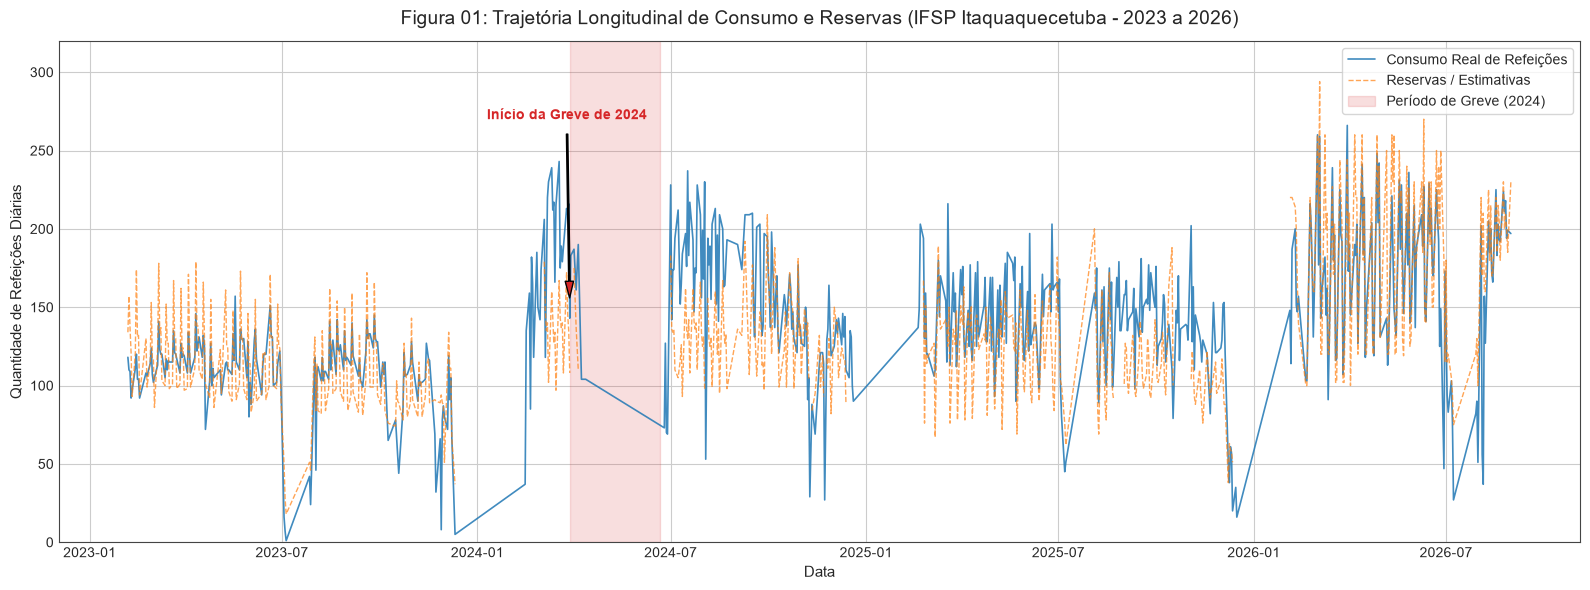

In [3]:
# Fig 01: Série Temporal Completa com Marcos Históricos
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(df_consumo["data_dt"], df_consumo["consumo"], color="#1f77b4", label="Consumo Real de Refeições", alpha=0.85, lw=1.2)
ax.plot(df_consumo["data_dt"], df_consumo["reservas"], color="#ff7f0e", linestyle="--", label="Reservas / Estimativas", alpha=0.7, lw=1.0)

# Demarcar greve de 2024
greve_ini = pd.to_datetime("2024-03-28")
greve_fim = pd.to_datetime("2024-06-21")
ax.axvspan(greve_ini, greve_fim, color="#d62728", alpha=0.15, label="Período de Greve (2024)")

# Anotações visuais
ax.annotate("Início da Greve de 2024", xy=(greve_ini, 150), xytext=(pd.to_datetime("2024-01-10"), 270),
            arrowprops=dict(facecolor="#d62728", shrink=0.05, width=1, headwidth=6),
            fontsize=10, fontweight="bold", color="#d62728")


ax.set_title("Figura 01: Trajetória Longitudinal de Consumo e Reservas (IFSP Itaquaquecetuba - 2023 a 2026)", fontsize=14, pad=12)
ax.set_xlabel("Data")
ax.set_ylabel("Quantidade de Refeições Diárias")
ax.set_ylim(0, 320)
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig01_serie_temporal_consumo_reservas.png", dpi=300, bbox_inches='tight')
plt.show()

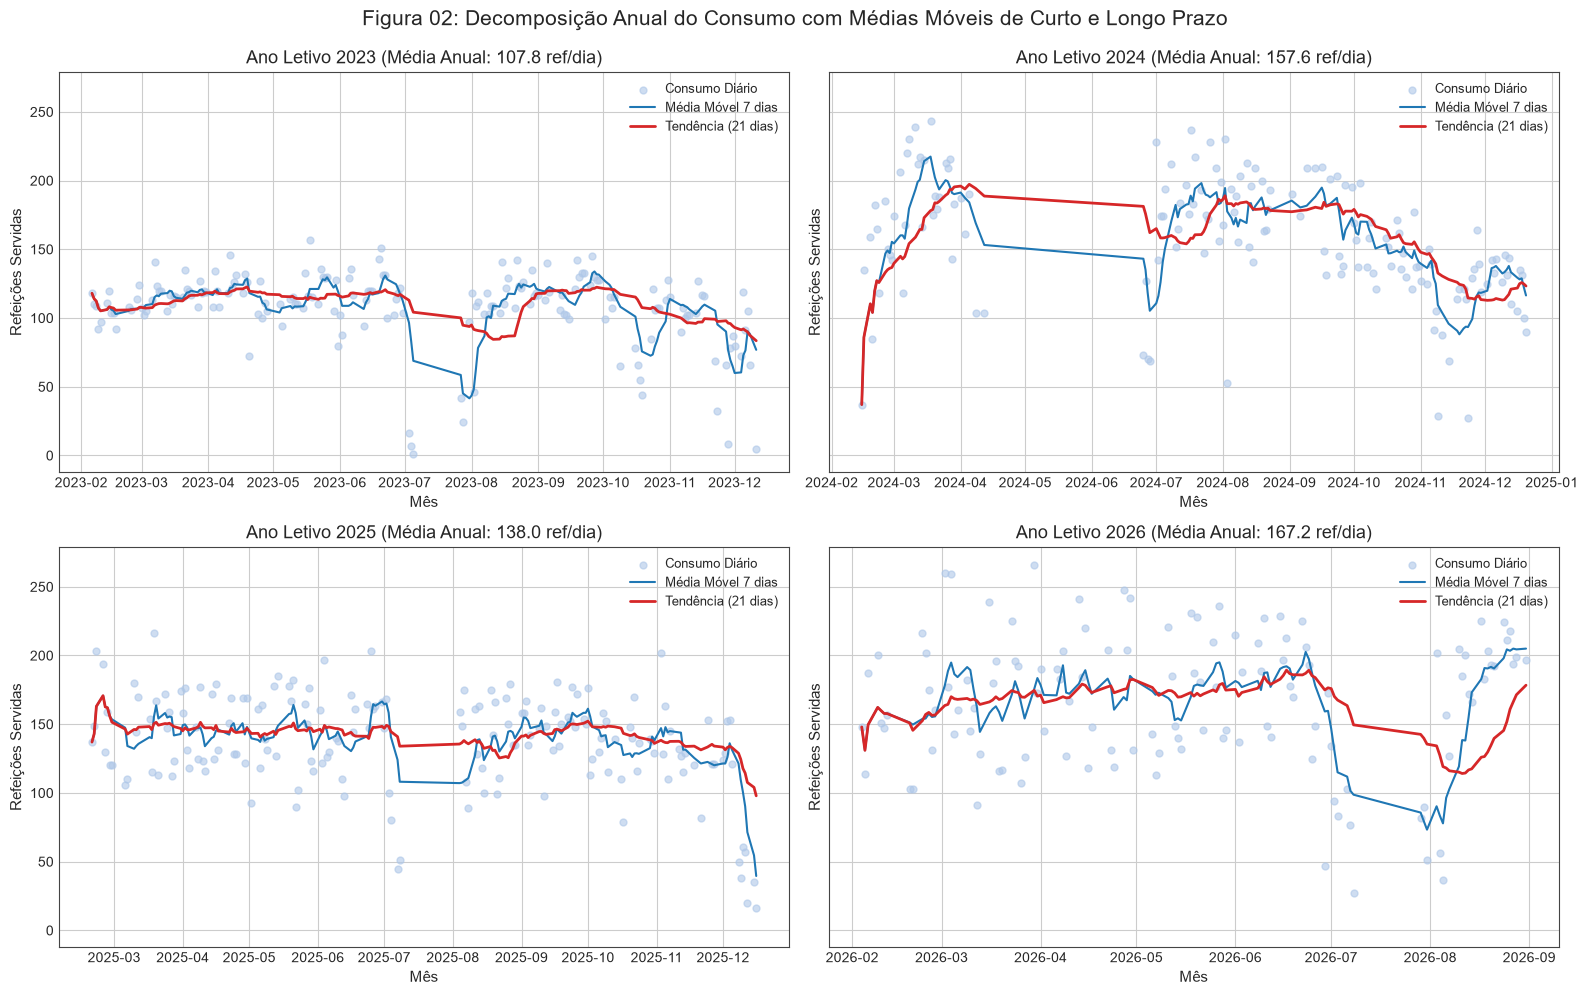

In [4]:
# Fig 02: Decomposição Anual e Médias Móveis de Tendência (Painel 2x2)
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
anos = [2023, 2024, 2025, 2026]

for ax, ano in zip(axes.flatten(), anos):
    sub = df_consumo[df_consumo["ano"] == ano].sort_values("data_dt").copy()
    sub["media_movel_7d"] = sub["consumo"].rolling(window=7, min_periods=1).mean()
    sub["media_movel_21d"] = sub["consumo"].rolling(window=21, min_periods=1).mean()
    
    ax.scatter(sub["data_dt"], sub["consumo"], color="#aec7e8", alpha=0.6, s=25, label="Consumo Diário")
    ax.plot(sub["data_dt"], sub["media_movel_7d"], color="#1f77b4", lw=1.5, label="Média Móvel 7 dias")
    ax.plot(sub["data_dt"], sub["media_movel_21d"], color="#d62728", lw=2.0, label="Tendência (21 dias)")
    
    ax.set_title(f"Ano Letivo {ano} (Média Anual: {sub['consumo'].mean():.1f} ref/dia)")
    ax.set_xlabel("Mês")
    ax.set_ylabel("Refeições Servidas")
    ax.legend(loc="upper right", fontsize=9)

plt.suptitle("Figura 02: Decomposição Anual do Consumo com Médias Móveis de Curto e Longo Prazo", fontsize=15, y=0.99)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig02_decomposicao_anual_medias_moveis.png", dpi=300, bbox_inches='tight')
plt.show()

C:\Users\miche\AppData\Local\Temp\ipykernel_23716\1175682067.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(ax=axes[0], data=df_consumo, x="ano", y="consumo", palette="Blues", inner="quartile")


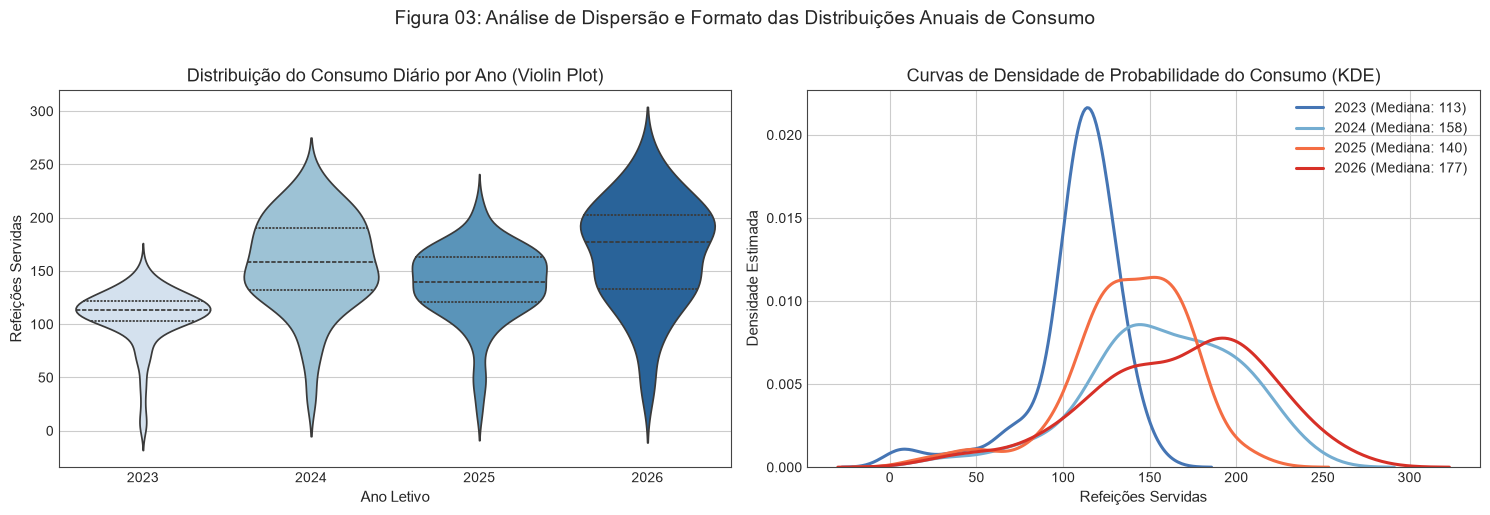

In [5]:
# Fig 03: Distribuições de Densidade e Formato das Distribuições Anuais
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.violinplot(ax=axes[0], data=df_consumo, x="ano", y="consumo", palette="Blues", inner="quartile")
axes[0].set_title("Distribuição do Consumo Diário por Ano (Violin Plot)")
axes[0].set_xlabel("Ano Letivo")
axes[0].set_ylabel("Refeições Servidas")

for ano, col in zip([2023, 2024, 2025, 2026], ["#4575b4", "#74add1", "#f46d43", "#d73027"]):
    s = df_consumo[df_consumo["ano"] == ano]["consumo"].dropna()
    sns.kdeplot(ax=axes[1], data=s, label=f"{ano} (Mediana: {s.median():.0f})", color=col, lw=2.2)

axes[1].set_title("Curvas de Densidade de Probabilidade do Consumo (KDE)")
axes[1].set_xlabel("Refeições Servidas")
axes[1].set_ylabel("Densidade Estimada")
axes[1].legend()

plt.suptitle("Figura 03: Análise de Dispersão e Formato das Distribuições Anuais de Consumo", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig03_distribuicoes_densidade_anuais.png", dpi=300, bbox_inches='tight')
plt.show()

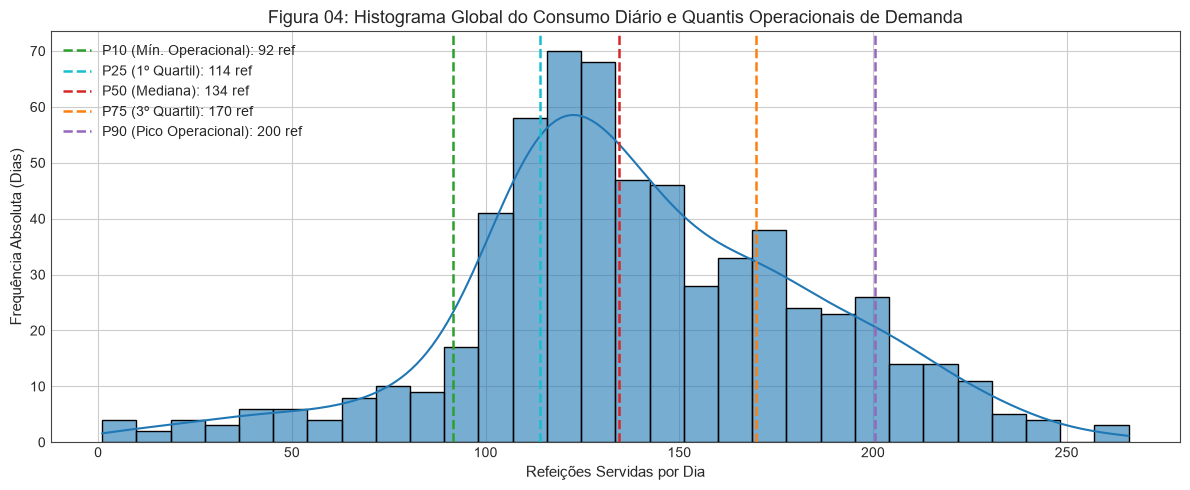

In [6]:
# Fig 04: Histograma Global com Quantis Operacionais
fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(df_consumo["consumo"], kde=True, color="#1f77b4", bins=30, ax=ax, alpha=0.6)

q10 = df_consumo["consumo"].quantile(0.10)
q25 = df_consumo["consumo"].quantile(0.25)
q50 = df_consumo["consumo"].quantile(0.50)
q75 = df_consumo["consumo"].quantile(0.75)
q90 = df_consumo["consumo"].quantile(0.90)

for q, label, col in zip([q10, q25, q50, q75, q90], 
                         ["P10 (Mín. Operacional)", "P25 (1º Quartil)", "P50 (Mediana)", "P75 (3º Quartil)", "P90 (Pico Operacional)"],
                         ["#2ca02c", "#17becf", "#d62728", "#ff7f0e", "#9467bd"]):
    ax.axvline(q, color=col, linestyle="--", lw=1.8, label=f"{label}: {q:.0f} ref")

ax.set_title("Figura 04: Histograma Global do Consumo Diário e Quantis Operacionais de Demanda", fontsize=13)
ax.set_xlabel("Refeições Servidas por Dia")
ax.set_ylabel("Frequência Absoluta (Dias)")
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig04_histograma_global_quantis.png", dpi=300, bbox_inches='tight')
plt.show()

## ⚖️ Bloco B: Confronto Reserva vs. Consumo Real e Balanço Falta vs. Sobra
Análise empírica do trade-off operacional: subnotificação (risco de falta de comida) versus superestimativa (desperdício/sobra).

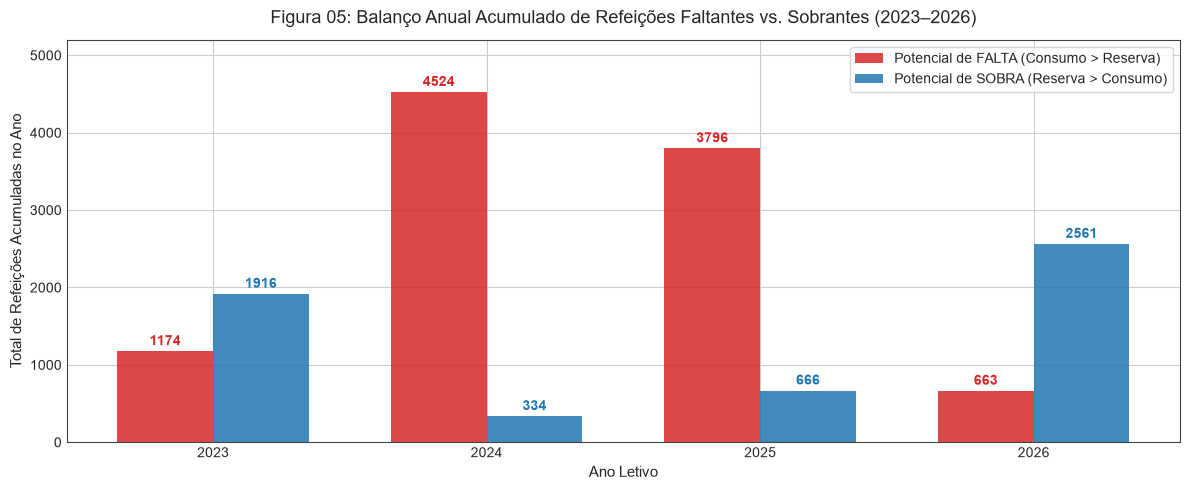

In [7]:
# Fig 05: Balanço Total de Refeições Faltantes vs. Sobrantes por Ano
resumo_sobra_falta = df_cr.groupby("ano").agg(
    total_falta=("falta", "sum"),
    total_sobra=("sobra", "sum")
).reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(resumo_sobra_falta))
width = 0.35

b1 = ax.bar(x - width/2, resumo_sobra_falta["total_falta"], width, label="Potencial de FALTA (Consumo > Reserva)", color="#d62728", alpha=0.85)
b2 = ax.bar(x + width/2, resumo_sobra_falta["total_sobra"], width, label="Potencial de SOBRA (Reserva > Consumo)", color="#1f77b4", alpha=0.85)

for bar in b1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80, f"{int(bar.get_height())}", ha="center", color="#d62728", fontweight="bold")
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80, f"{int(bar.get_height())}", ha="center", color="#1f77b4", fontweight="bold")

ax.set_title("Figura 05: Balanço Anual Acumulado de Refeições Faltantes vs. Sobrantes (2023–2026)", fontsize=13, pad=12)
ax.set_xlabel("Ano Letivo")
ax.set_ylabel("Total de Refeições Acumuladas no Ano")
ax.set_xticks(x)
ax.set_xticklabels(resumo_sobra_falta["ano"])
ax.set_ylim(0, 5200)
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig05_balanco_anual_falta_sobra.png", dpi=300, bbox_inches='tight')
plt.show()

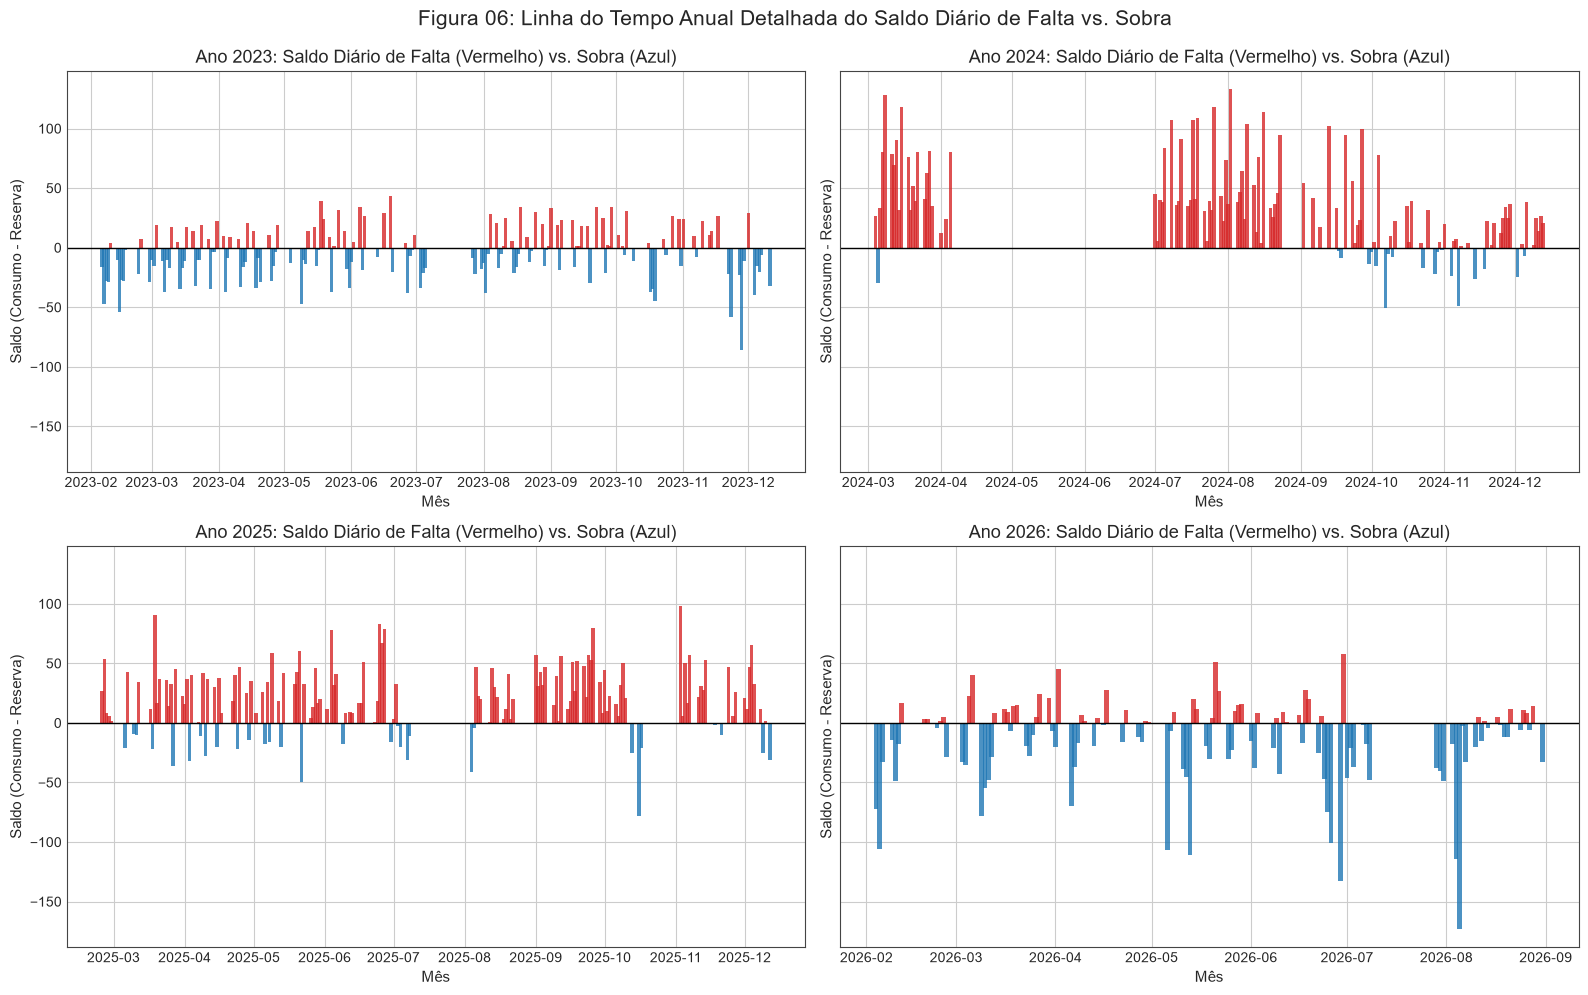

In [8]:
# Fig 06: Painel Desdobrado por Ano (2x2) do Saldo Diário (Consumo - Reserva)
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)

for ax, ano in zip(axes.flatten(), anos):
    sub = df_cr[df_cr["ano"] == ano].sort_values("data_dt").copy()
    sub["saldo"] = sub["consumo"] - sub["reservas"]
    cores = ["#d62728" if v > 0 else "#1f77b4" for v in sub["saldo"]]
    
    ax.bar(sub["data_dt"], sub["saldo"], color=cores, width=1.5, alpha=0.8)
    ax.axhline(0, color="black", lw=1)
    ax.set_title(f"Ano {ano}: Saldo Diário de Falta (Vermelho) vs. Sobra (Azul)")
    ax.set_xlabel("Mês")
    ax.set_ylabel("Saldo (Consumo - Reserva)")

plt.suptitle("Figura 06: Linha do Tempo Anual Detalhada do Saldo Diário de Falta vs. Sobra", fontsize=15, y=0.99)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig06_painel_anual_saldo_falta_sobra.png", dpi=300, bbox_inches='tight')
plt.show()

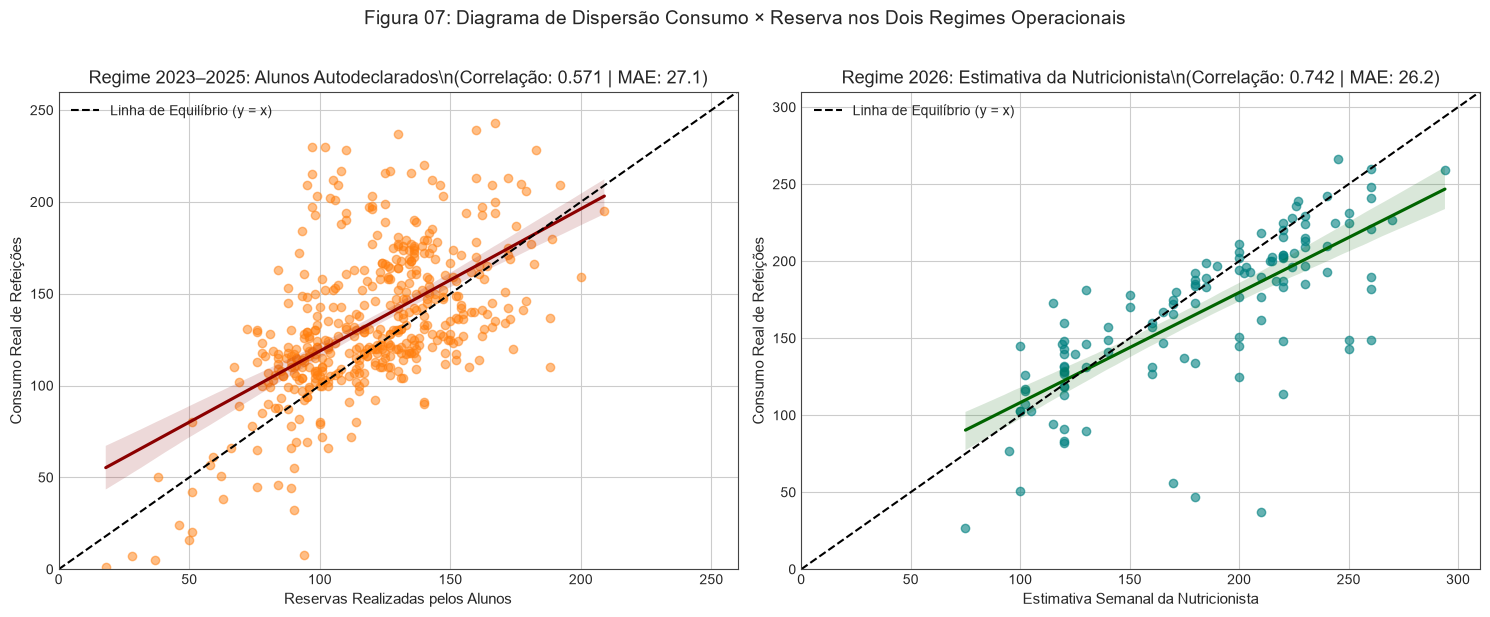

In [9]:
# Fig 07: Dispersão Consumo vs. Reserva com Linhas de Identidade por Regime
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

df_aluno = df_cr[df_cr["regime_reserva"] == "aluno_manifestacao"]
df_nutri = df_cr[df_cr["regime_reserva"] == "nutricionista_estimativa"]

# Alunos
sns.regplot(ax=axes[0], data=df_aluno, x="reservas", y="consumo", scatter_kws={"alpha": 0.5, "color": "#ff7f0e"}, line_kws={"color": "darkred"})
axes[0].plot([0, 260], [0, 260], "k--", lw=1.5, label="Linha de Equilíbrio (y = x)")
axes[0].set_title(f"Regime 2023–2025: Alunos Autodeclarados\\n(Correlação: {df_aluno['consumo'].corr(df_aluno['reservas']):.3f} | MAE: {(df_aluno['consumo']-df_aluno['reservas']).abs().mean():.1f})")
axes[0].set_xlabel("Reservas Realizadas pelos Alunos")
axes[0].set_ylabel("Consumo Real de Refeições")
axes[0].set_xlim(0, 260)
axes[0].set_ylim(0, 260)
axes[0].legend(loc="upper left")

# Nutricionista
sns.regplot(ax=axes[1], data=df_nutri, x="reservas", y="consumo", scatter_kws={"alpha": 0.6, "color": "teal"}, line_kws={"color": "darkgreen"})
axes[1].plot([0, 310], [0, 310], "k--", lw=1.5, label="Linha de Equilíbrio (y = x)")
axes[1].set_title(f"Regime 2026: Estimativa da Nutricionista\\n(Correlação: {df_nutri['consumo'].corr(df_nutri['reservas']):.3f} | MAE: {(df_nutri['consumo']-df_nutri['reservas']).abs().mean():.1f})")
axes[1].set_xlabel("Estimativa Semanal da Nutricionista")
axes[1].set_ylabel("Consumo Real de Refeições")
axes[1].set_xlim(0, 310)
axes[1].set_ylim(0, 310)
axes[1].legend(loc="upper left")

plt.suptitle("Figura 07: Diagrama de Dispersão Consumo × Reserva nos Dois Regimes Operacionais", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig07_dispersao_consumo_reserva_regimes.png", dpi=300, bbox_inches='tight')
plt.show()

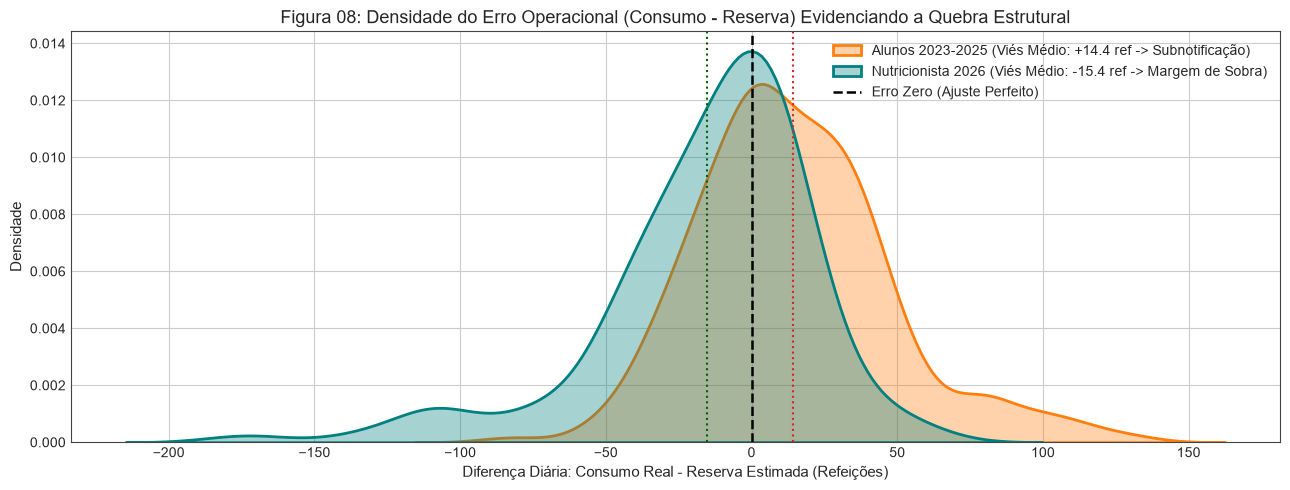

In [10]:
# Fig 08: Densidade do Viés Operacional (Consumo - Reserva) por Regime
fig, ax = plt.subplots(figsize=(13, 5))

erro_aluno = (df_aluno["consumo"] - df_aluno["reservas"]).dropna()
erro_nutri = (df_nutri["consumo"] - df_nutri["reservas"]).dropna()

sns.kdeplot(erro_aluno, ax=ax, color="#ff7f0e", fill=True, alpha=0.35, label=f"Alunos 2023-2025 (Viés Médio: +{erro_aluno.mean():.1f} ref -> Subnotificação)", lw=2)
sns.kdeplot(erro_nutri, ax=ax, color="teal", fill=True, alpha=0.35, label=f"Nutricionista 2026 (Viés Médio: {erro_nutri.mean():.1f} ref -> Margem de Sobra)", lw=2)

ax.axvline(0, color="black", linestyle="--", lw=1.8, label="Erro Zero (Ajuste Perfeito)")
ax.axvline(erro_aluno.mean(), color="#d62728", linestyle=":", lw=1.5)
ax.axvline(erro_nutri.mean(), color="darkgreen", linestyle=":", lw=1.5)

ax.set_title("Figura 08: Densidade do Erro Operacional (Consumo - Reserva) Evidenciando a Quebra Estrutural", fontsize=13)
ax.set_xlabel("Diferença Diária: Consumo Real - Reserva Estimada (Refeições)")
ax.set_ylabel("Densidade")
ax.legend(loc="upper right")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig08_distribuicao_vies_erro_reserva.png", dpi=300, bbox_inches='tight')
plt.show()

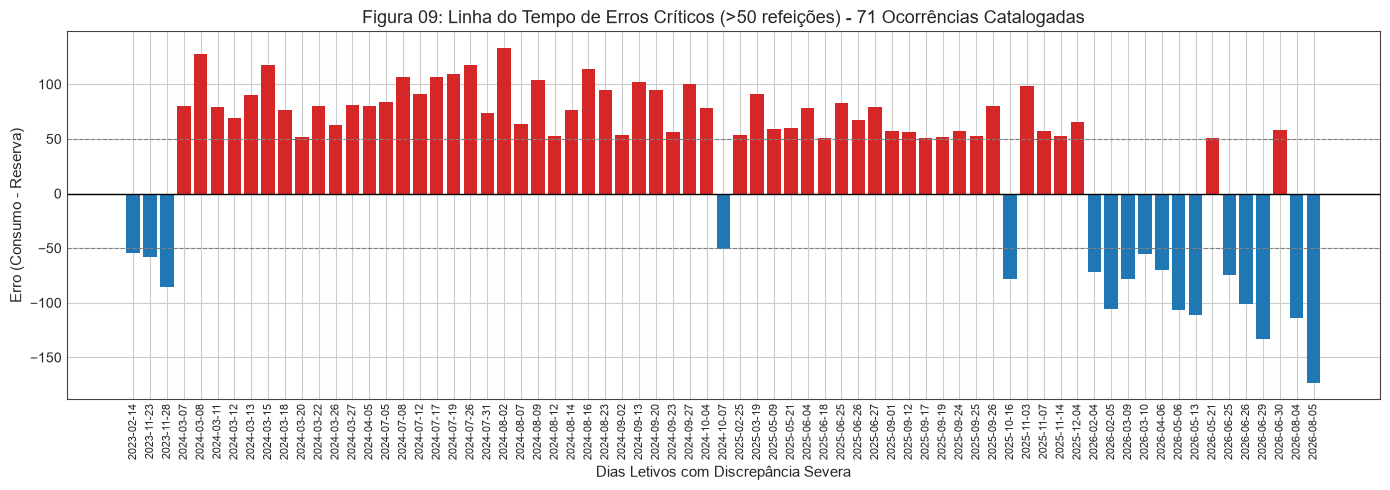

In [11]:
# Fig 09: Linha do Tempo de Erros Críticos (>50 refeições)
df_discrepantes = df_cr[df_cr["diff_consumo_reserva"].abs() > 50].copy()

fig, ax = plt.subplots(figsize=(14, 5))
cores = ["#d62728" if v > 0 else "#1f77b4" for v in df_discrepantes["diff_consumo_reserva"]]

ax.bar(df_discrepantes["data_iso"], df_discrepantes["diff_consumo_reserva"], color=cores, width=0.8)
ax.axhline(0, color="black", lw=1)
ax.axhline(50, color="gray", linestyle="--", lw=0.8)
ax.axhline(-50, color="gray", linestyle="--", lw=0.8)

ax.set_title(f"Figura 09: Linha do Tempo de Erros Críticos (>50 refeições) - {len(df_discrepantes)} Ocorrências Catalogadas", fontsize=13)
ax.set_xlabel("Dias Letivos com Discrepância Severa")
ax.set_ylabel("Erro (Consumo - Reserva)")
ax.tick_params(axis='x', rotation=90, labelsize=8)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig09_discrepancias_severas_outliers.png", dpi=300, bbox_inches='tight')
plt.show()

## 🗓️ Bloco C: Sazonalidade Semanal e Mensal Desdobradas por Ano
Para evitar sobrecarga de informação em um único gráfico, desdobramos os padrões anualmente em painéis facetados.

C:\Users\miche\AppData\Local\Temp\ipykernel_23716\1554673059.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=sub, x="dia_da_semana", y="consumo", order=ordem_dias, palette="Blues_r", errorbar="ci")
C:\Users\miche\AppData\Local\Temp\ipykernel_23716\1554673059.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=sub, x="dia_da_semana", y="consumo", order=ordem_dias, palette="Blues_r", errorbar="ci")


C:\Users\miche\AppData\Local\Temp\ipykernel_23716\1554673059.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=sub, x="dia_da_semana", y="consumo", order=ordem_dias, palette="Blues_r", errorbar="ci")
C:\Users\miche\AppData\Local\Temp\ipykernel_23716\1554673059.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=sub, x="dia_da_semana", y="consumo", order=ordem_dias, palette="Blues_r", errorbar="ci")


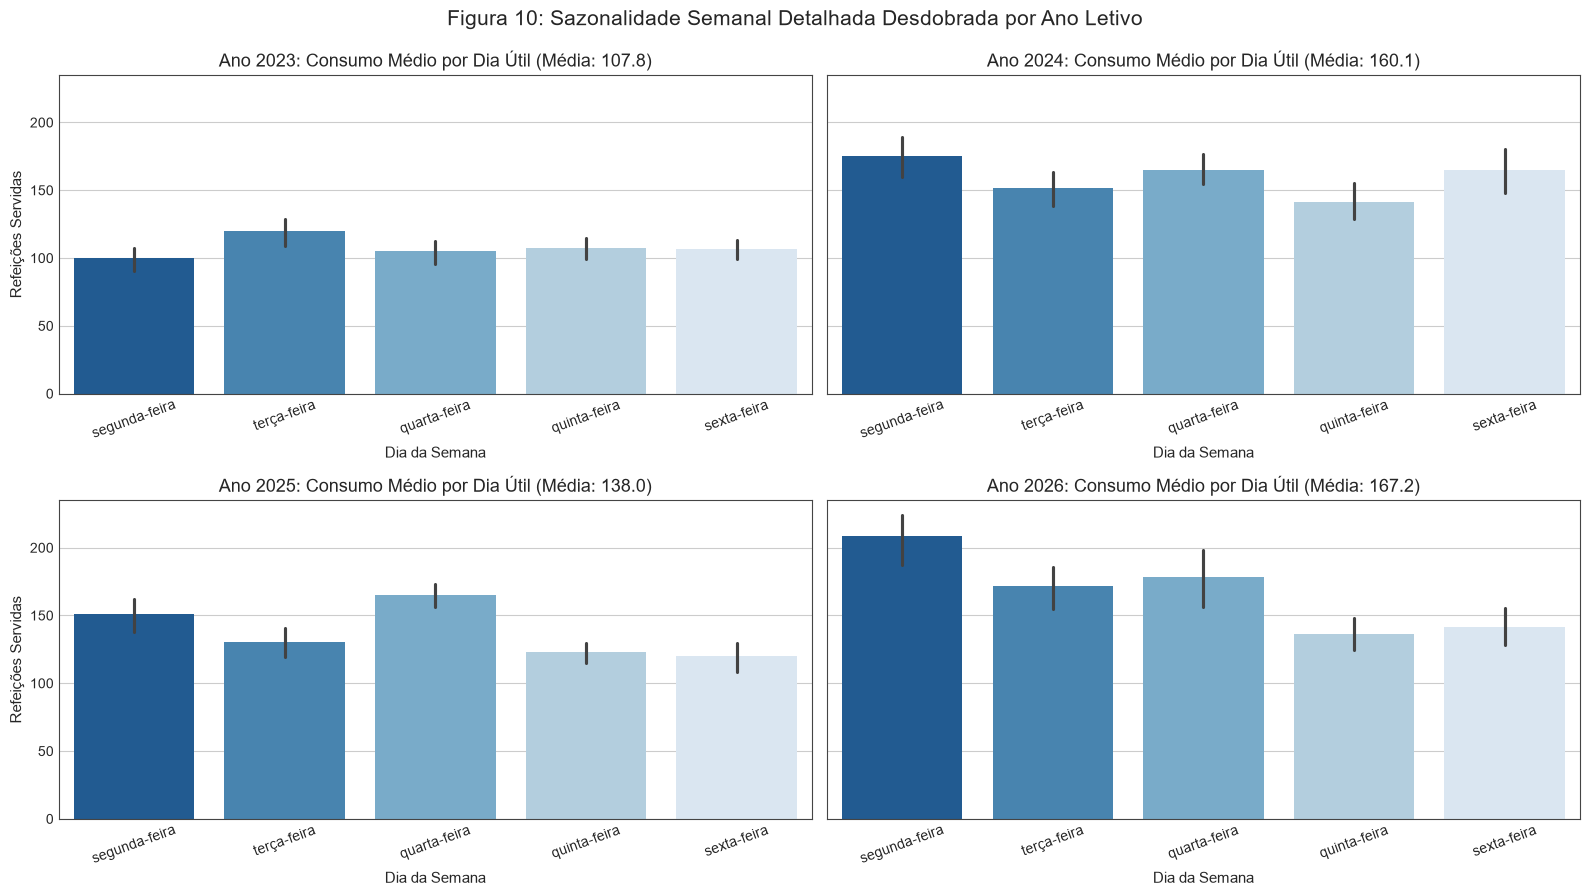

In [12]:
# Fig 10: Painel Anual (2x2) do Consumo por Dia da Semana
ordem_dias = ["segunda-feira", "terça-feira", "quarta-feira", "quinta-feira", "sexta-feira"]
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharey=True)

for ax, ano in zip(axes.flatten(), anos):
    sub = df_consumo[(df_consumo["ano"] == ano) & (df_consumo["dia_da_semana"].isin(ordem_dias))]
    sns.barplot(ax=ax, data=sub, x="dia_da_semana", y="consumo", order=ordem_dias, palette="Blues_r", errorbar="ci")
    ax.set_title(f"Ano {ano}: Consumo Médio por Dia Útil (Média: {sub['consumo'].mean():.1f})")
    ax.set_xlabel("Dia da Semana")
    ax.set_ylabel("Refeições Servidas")
    ax.tick_params(axis='x', rotation=20)

plt.suptitle("Figura 10: Sazonalidade Semanal Detalhada Desdobrada por Ano Letivo", fontsize=15, y=0.99)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig10_sazonalidade_semanal_por_ano.png", dpi=300, bbox_inches='tight')
plt.show()

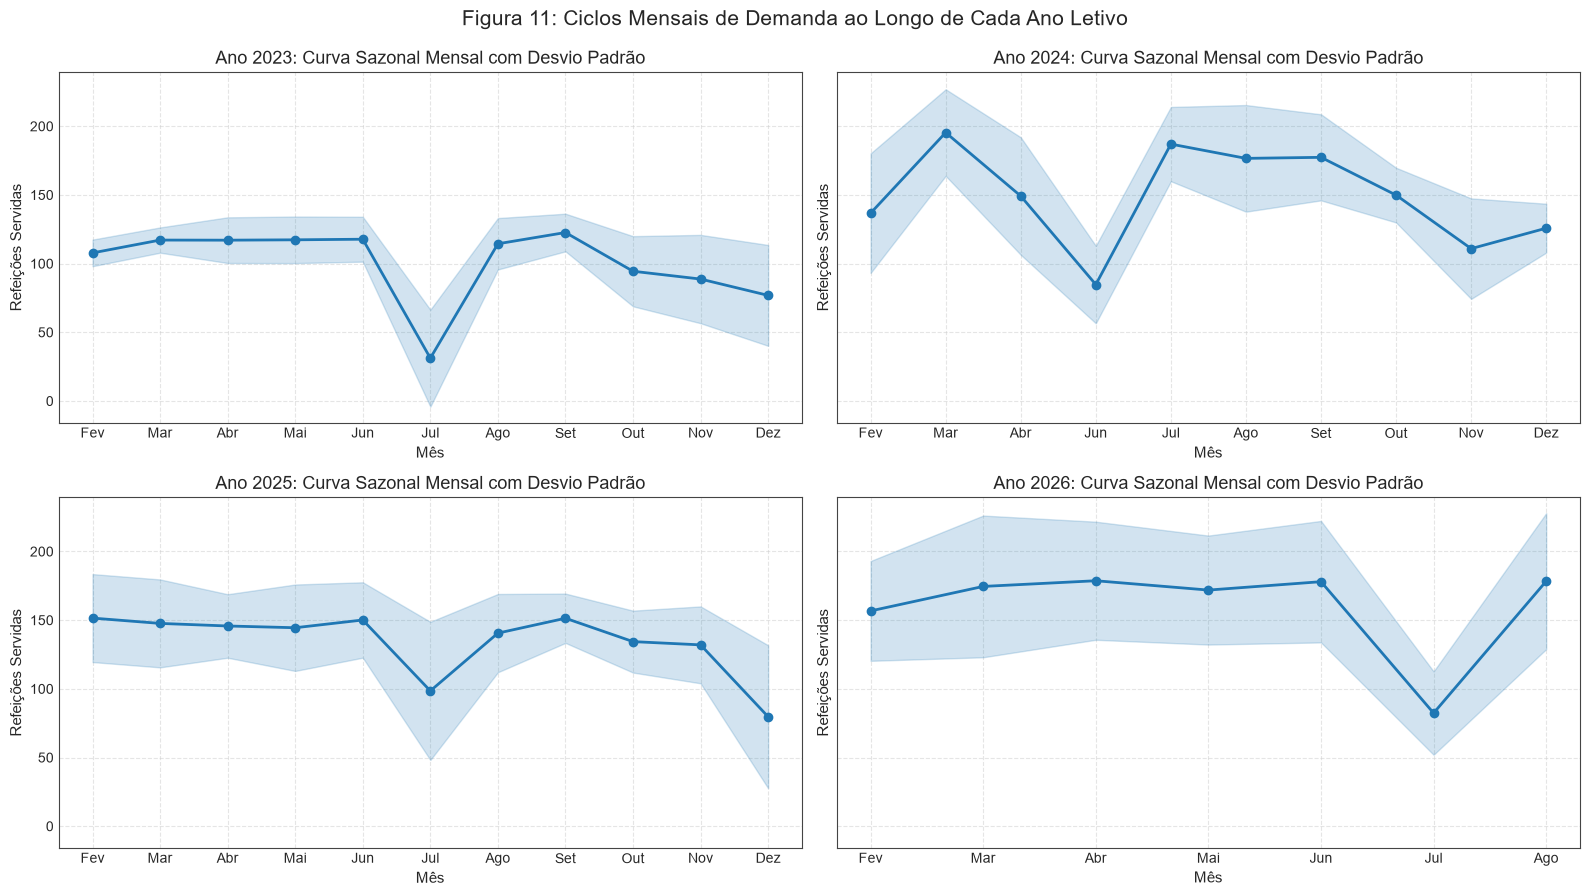

In [13]:
# Fig 11: Painel Anual (2x2) da Curva de Evolução Mensal do Consumo
mes_nomes = {1:"Jan", 2:"Fev", 3:"Mar", 4:"Abr", 5:"Mai", 6:"Jun", 7:"Jul", 8:"Ago", 9:"Set", 10:"Out", 11:"Nov", 12:"Dez"}
df_consumo["mes_nome"] = df_consumo["mes"].map(mes_nomes)

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharey=True)

for ax, ano in zip(axes.flatten(), anos):
    sub = df_consumo[df_consumo["ano"] == ano].groupby("mes")["consumo"].agg(["mean", "std", "count"]).reset_index()
    sub["mes_nome"] = sub["mes"].map(mes_nomes)
    
    ax.plot(sub["mes_nome"], sub["mean"], marker="o", color="#1f77b4", lw=2, label="Consumo Médio")
    ax.fill_between(sub["mes_nome"], sub["mean"] - sub["std"].fillna(0), sub["mean"] + sub["std"].fillna(0), color="#1f77b4", alpha=0.2)
    
    ax.set_title(f"Ano {ano}: Curva Sazonal Mensal com Desvio Padrão")
    ax.set_xlabel("Mês")
    ax.set_ylabel("Refeições Servidas")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Figura 11: Ciclos Mensais de Demanda ao Longo de Cada Ano Letivo", fontsize=15, y=0.99)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig11_ciclos_mensais_por_ano.png", dpi=300, bbox_inches='tight')
plt.show()

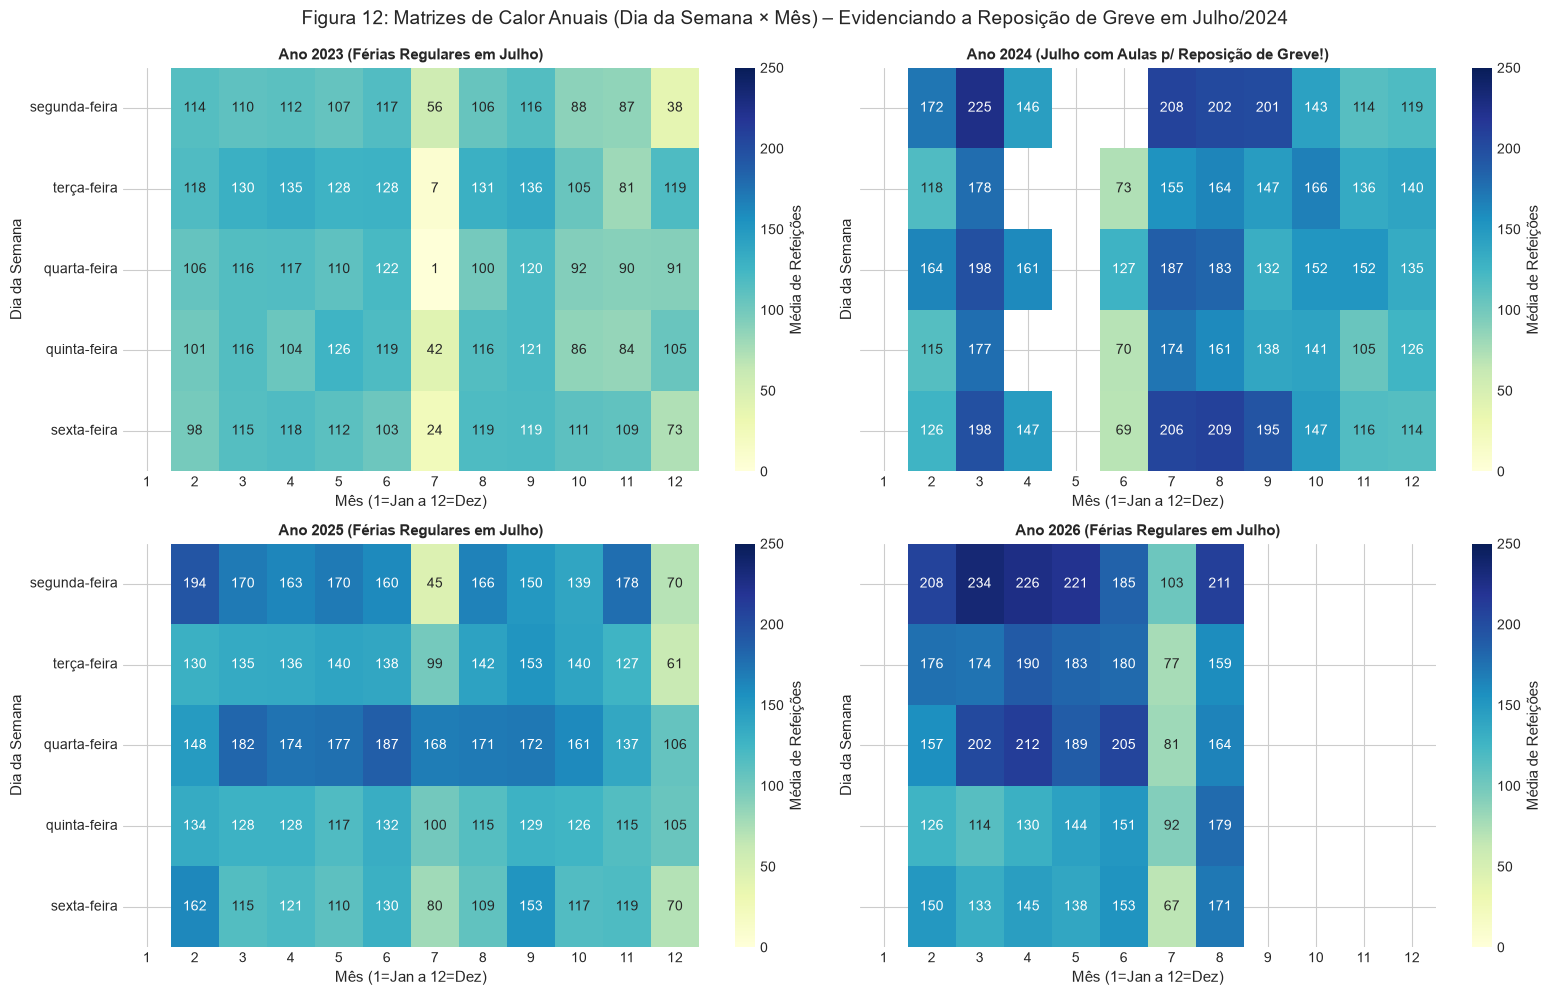

In [14]:
# Fig 12: Painel Anual (2x2) de Heatmaps (Dia da Semana × Mês Letivo por Ano)
# Evidencia o impacto da reposição da greve de 2024 em julho vs. anos regulares de férias
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)

for ax, ano in zip(axes.flatten(), anos):
    sub = df_consumo[(df_consumo["ano"] == ano) & (df_consumo["dia_da_semana"].isin(ordem_dias))]
    pivot = sub.pivot_table(index="dia_da_semana", columns="mes", values="consumo", aggfunc="mean").reindex(index=ordem_dias)
    # Reindexar colunas de 1 a 12 para visualização completa
    pivot = pivot.reindex(columns=range(1, 13))
    
    sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar_kws={'label': 'Média de Refeições'}, vmin=0, vmax=250)
    
    nota = " (Férias Regulares em Julho)" if ano in [2023, 2025, 2026] else " (Julho com Aulas p/ Reposição de Greve!)"
    ax.set_title(f"Ano {ano}{nota}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Mês (1=Jan a 12=Dez)")
    ax.set_ylabel("Dia da Semana")

plt.suptitle("Figura 12: Matrizes de Calor Anuais (Dia da Semana × Mês) – Evidenciando a Reposição de Greve em Julho/2024", fontsize=14, y=0.99)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig12_heatmap_dia_semana_mes.png", dpi=300, bbox_inches='tight')
plt.show()

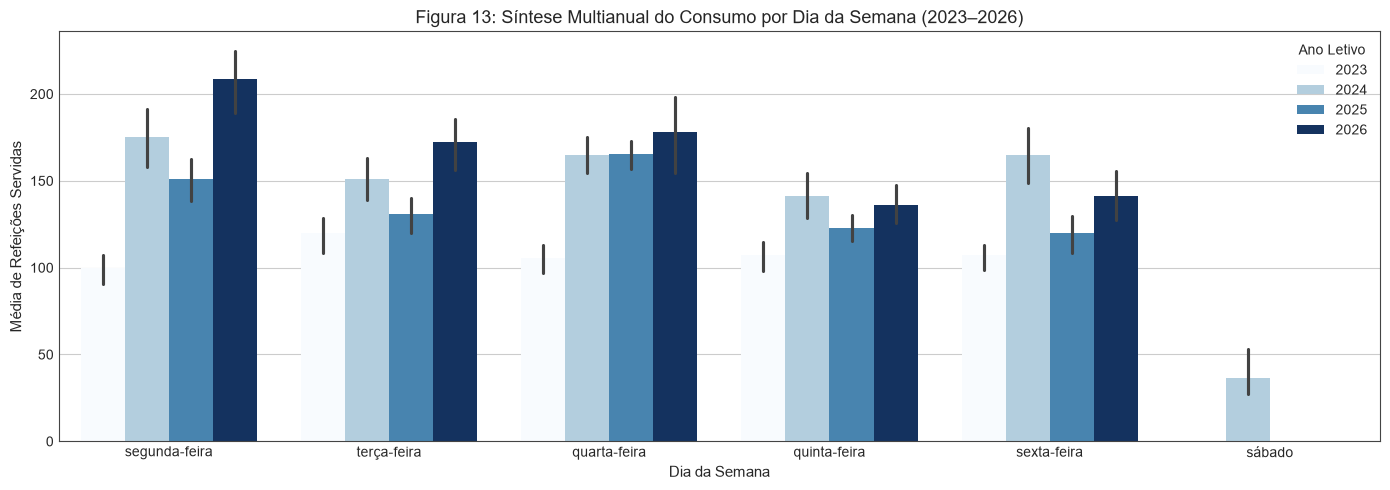

In [15]:
# Fig 13: Comparativo Geral de Consumo por Dia da Semana Agrupado por Ano
fig, ax = plt.subplots(figsize=(14, 5))
dias_existentes = [d for d in ordem_dias + ["sábado"] if d in df_consumo["dia_da_semana"].unique()]

sns.barplot(ax=ax, data=df_consumo, x="dia_da_semana", y="consumo", hue="ano", order=dias_existentes, palette="Blues")
ax.set_title("Figura 13: Síntese Multianual do Consumo por Dia da Semana (2023–2026)", fontsize=13)
ax.set_xlabel("Dia da Semana")
ax.set_ylabel("Média de Refeições Servidas")
ax.legend(title="Ano Letivo", loc="upper right")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig13_consumo_dia_semana_sintese.png", dpi=300, bbox_inches='tight')
plt.show()

## 🎓 Bloco D: Calendário Acadêmico e Taxas de Evasão/No-Show

C:\Users\miche\AppData\Local\Temp\ipykernel_23716\3138014312.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=ax, data=df_eventos, x="evento_tipo", y="consumo", palette="Set2")


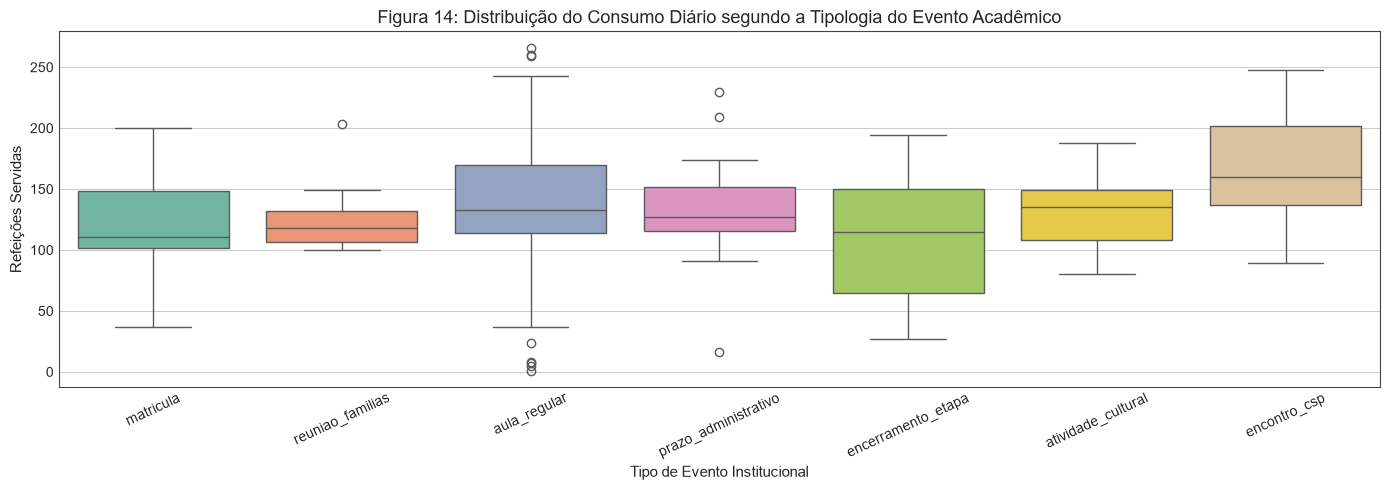

In [16]:
# Fig 14: Impacto dos Tipos de Eventos do Calendário Acadêmico
top_eventos = df_consumo["evento_tipo"].value_counts().index[:7]
df_eventos = df_consumo[df_consumo["evento_tipo"].isin(top_eventos)].copy()

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(ax=ax, data=df_eventos, x="evento_tipo", y="consumo", palette="Set2")
ax.set_title("Figura 14: Distribuição do Consumo Diário segundo a Tipologia do Evento Acadêmico", fontsize=13)
ax.set_xlabel("Tipo de Evento Institucional")
ax.set_ylabel("Refeições Servidas")
ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig14_consumo_por_tipo_evento.png", dpi=300, bbox_inches='tight')
plt.show()

C:\Users\miche\AppData\Local\Temp\ipykernel_23716\861910900.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=ax, data=df_dias_validos, x="dia_da_semana", y="taxa_no_show_pct", order=ordem_dias, palette="Reds_d", errorbar="ci")


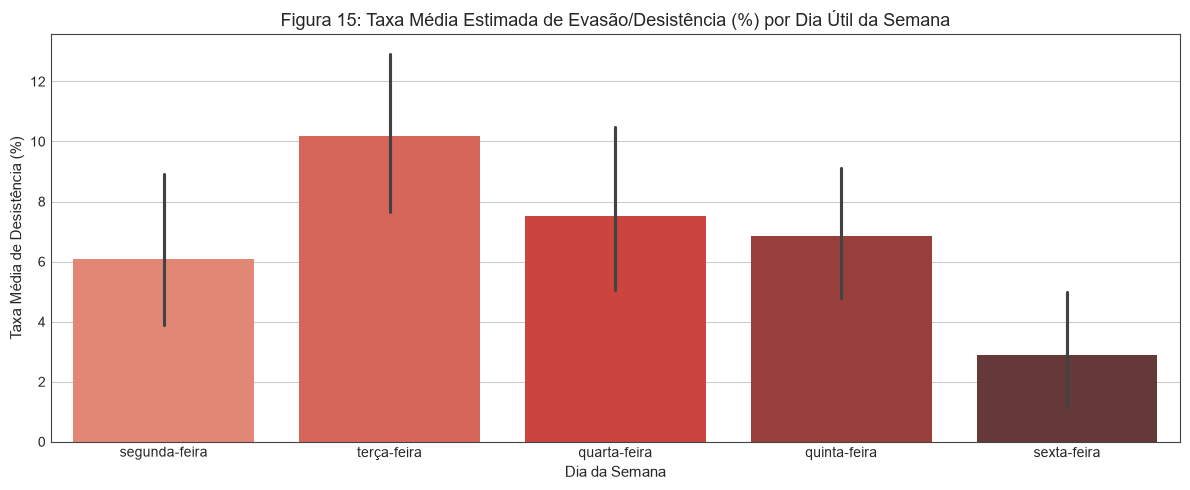

In [17]:
# Fig 15: Taxa de Evasão/No-Show Estimada por Dia da Semana
df_dias_validos = df_cr[df_cr["dia_da_semana"].isin(ordem_dias)].copy()
df_dias_validos["taxa_no_show_pct"] = np.maximum(0, (1.0 - (df_dias_validos["consumo"] / df_dias_validos["reservas"]))) * 100

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(ax=ax, data=df_dias_validos, x="dia_da_semana", y="taxa_no_show_pct", order=ordem_dias, palette="Reds_d", errorbar="ci")
ax.set_title("Figura 15: Taxa Média Estimada de Evasão/Desistência (%) por Dia Útil da Semana", fontsize=13)
ax.set_xlabel("Dia da Semana")
ax.set_ylabel("Taxa Média de Desistência (%)")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig15_taxa_noshow_dia_semana.png", dpi=300, bbox_inches='tight')
plt.show()

## 🍗 Bloco E: Engenharia e Atratividade do Cardápio
Análise aprofundada da influência do cardápio sobre o quantitativo de refeições servidas e sobre as sobras/faltas.

C:\Users\miche\AppData\Local\Temp\ipykernel_23716\1835180326.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=prot_stats, x="proteina_tipo", y="frequencia_dias", palette="Blues_d")
C:\Users\miche\AppData\Local\Temp\ipykernel_23716\1835180326.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=prot_stats, x="proteina_tipo", y="consumo_medio_ref", palette="YlOrBr_r")


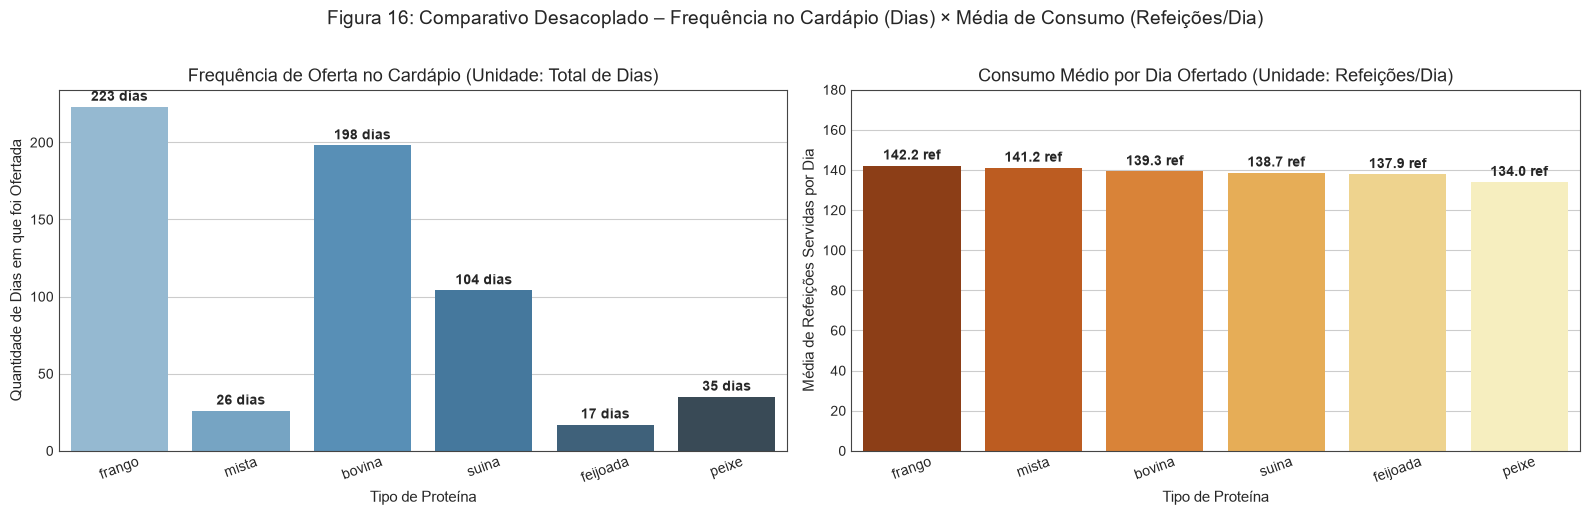

In [18]:
# Fig 16: Frequência de Oferta (Dias) vs. Consumo Médio (Refeições/Dia) por Proteína
# Separado em dois subplots claros para evitar a confusão de grandezas/unidades diferentes
prot_stats = df_card.groupby("proteina_tipo").agg(
    frequencia_dias=("consumo", "count"),
    consumo_medio_ref=("consumo", "mean")
).sort_values("consumo_medio_ref", ascending=False).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 1: Frequência de Oferta (Unidade: DIAS)
sns.barplot(ax=axes[0], data=prot_stats, x="proteina_tipo", y="frequencia_dias", palette="Blues_d")
axes[0].set_title("Frequência de Oferta no Cardápio (Unidade: Total de Dias)")
axes[0].set_xlabel("Tipo de Proteína")
axes[0].set_ylabel("Quantidade de Dias em que foi Ofertada")
axes[0].tick_params(axis='x', rotation=20)
for i, v in enumerate(prot_stats["frequencia_dias"]):
    axes[0].text(i, v + 4, f"{v} dias", ha="center", fontweight="bold", fontsize=10)

# Subplot 2: Consumo Médio (Unidade: REFEIÇÕES POR DIA)
sns.barplot(ax=axes[1], data=prot_stats, x="proteina_tipo", y="consumo_medio_ref", palette="YlOrBr_r")
axes[1].set_title("Consumo Médio por Dia Ofertado (Unidade: Refeições/Dia)")
axes[1].set_xlabel("Tipo de Proteína")
axes[1].set_ylabel("Média de Refeições Servidas por Dia")
axes[1].set_ylim(0, 180)
axes[1].tick_params(axis='x', rotation=20)
for i, v in enumerate(prot_stats["consumo_medio_ref"]):
    axes[1].text(i, v + 3, f"{v:.1f} ref", ha="center", fontweight="bold", fontsize=10)

plt.suptitle("Figura 16: Comparativo Desacoplado – Frequência no Cardápio (Dias) × Média de Consumo (Refeições/Dia)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig16_frequencia_vs_consumo_proteina.png", dpi=300, bbox_inches='tight')
plt.show()

C:\Users\miche\AppData\Local\Temp\ipykernel_23716\1438774765.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=ax, data=df_card[df_card["preparo_tipo"].isin(ordem_prep)], x="preparo_tipo", y="consumo", order=ordem_prep, palette="YlOrRd")


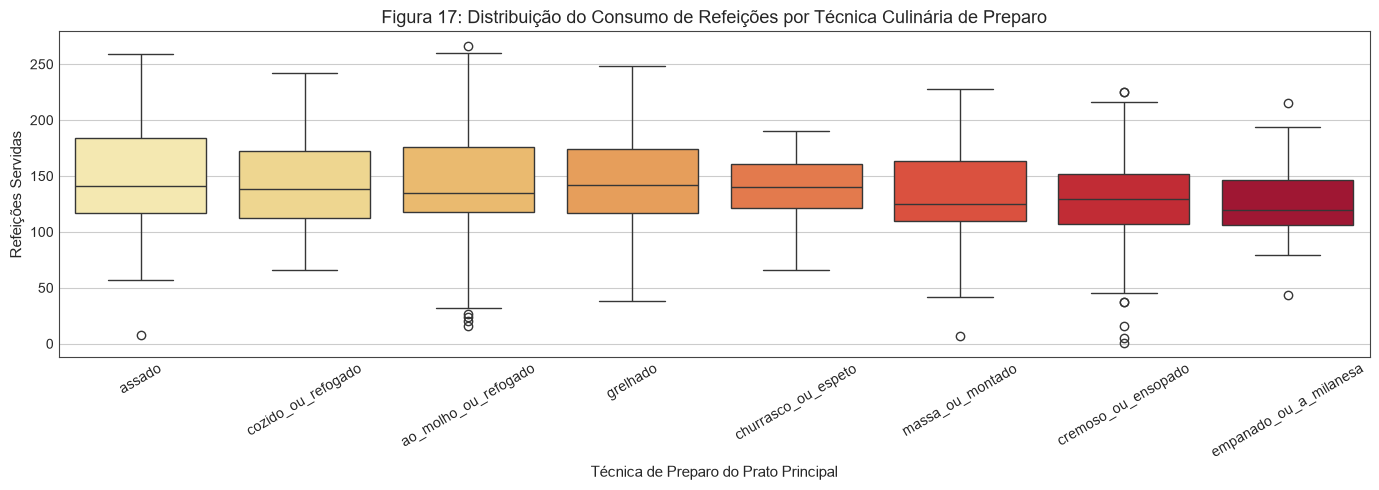

In [19]:
# Fig 17: Consumo por Técnica Culinária de Preparo
prep_stats = df_card.groupby("preparo_tipo")["consumo"].agg(["count", "mean", "std"]).sort_values("mean", ascending=False)
ordem_prep = prep_stats[prep_stats["count"] >= 5].index

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(ax=ax, data=df_card[df_card["preparo_tipo"].isin(ordem_prep)], x="preparo_tipo", y="consumo", order=ordem_prep, palette="YlOrRd")
ax.set_title("Figura 17: Distribuição do Consumo de Refeições por Técnica Culinária de Preparo", fontsize=13)
ax.set_xlabel("Técnica de Preparo do Prato Principal")
ax.set_ylabel("Refeições Servidas")
ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig17_consumo_por_tecnica_preparo.png", dpi=300, bbox_inches='tight')
plt.show()

C:\Users\miche\AppData\Local\Temp\ipykernel_23716\1043772942.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=top8, y="prato_principal", x="consumo_medio", palette="Greens_r")
C:\Users\miche\AppData\Local\Temp\ipykernel_23716\1043772942.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=bottom8, y="prato_principal", x="consumo_medio", palette="Oranges")


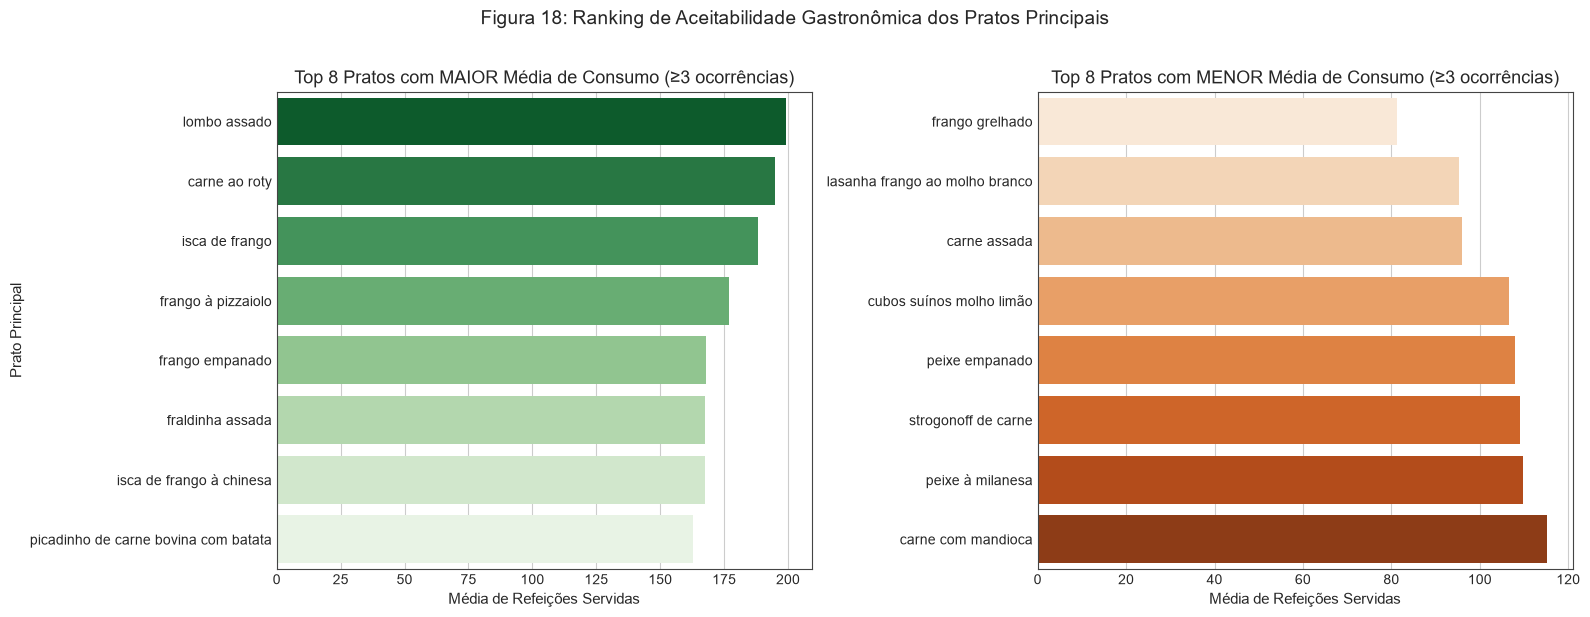

In [20]:
# Fig 18: Ranking dos Pratos Principais (Top 8 Maior vs Menor Consumo)
pratos_agg = df_card.groupby("prato_principal").agg(
    consumo_medio=("consumo", "mean"),
    qtd=("consumo", "count")
).reset_index()

pratos_validos = pratos_agg[pratos_agg["qtd"] >= 3]
top8 = pratos_validos.sort_values("consumo_medio", ascending=False).head(8)
bottom8 = pratos_validos.sort_values("consumo_medio", ascending=True).head(8)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(ax=axes[0], data=top8, y="prato_principal", x="consumo_medio", palette="Greens_r")
axes[0].set_title("Top 8 Pratos com MAIOR Média de Consumo (≥3 ocorrências)")
axes[0].set_xlabel("Média de Refeições Servidas")
axes[0].set_ylabel("Prato Principal")

sns.barplot(ax=axes[1], data=bottom8, y="prato_principal", x="consumo_medio", palette="Oranges")
axes[1].set_title("Top 8 Pratos com MENOR Média de Consumo (≥3 ocorrências)")
axes[1].set_xlabel("Média de Refeições Servidas")
axes[1].set_ylabel("")

plt.suptitle("Figura 18: Ranking de Aceitabilidade Gastronômica dos Pratos Principais", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig18_ranking_pratos_principais.png", dpi=300, bbox_inches='tight')
plt.show()

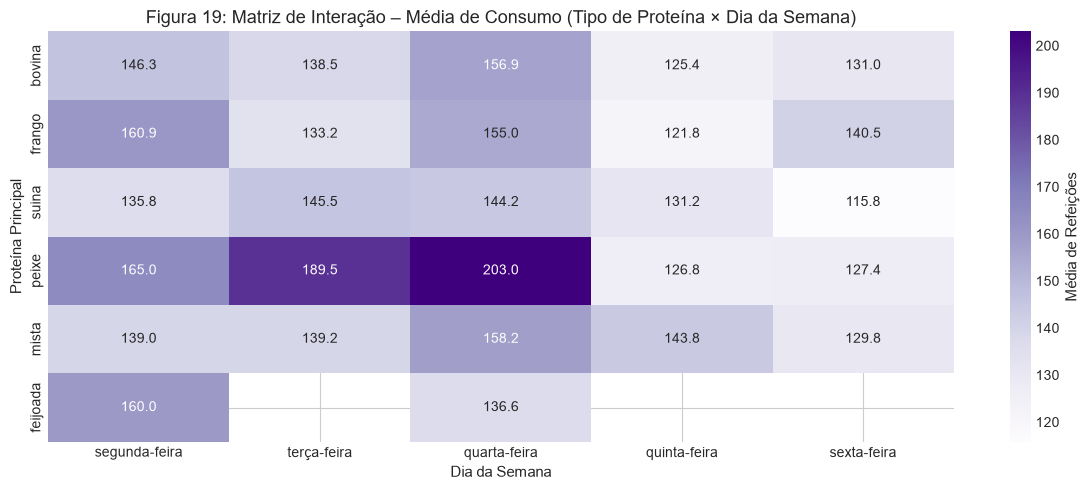

In [21]:
# Fig 19: Interação Cardápio × Dia da Semana (Heatmap Proteína x Dia)
top_prots = ["bovina", "frango", "suina", "peixe", "mista", "feijoada"]
sub_prot_dia = df_card[df_card["proteina_tipo"].isin(top_prots) & df_card["dia_da_semana"].isin(ordem_dias)]

pivot_prot_dia = sub_prot_dia.pivot_table(index="proteina_tipo", columns="dia_da_semana", values="consumo", aggfunc="mean").reindex(columns=ordem_dias, index=top_prots)

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(pivot_prot_dia, annot=True, fmt=".1f", cmap="Purples", ax=ax, cbar_kws={'label': 'Média de Refeições'})
ax.set_title("Figura 19: Matriz de Interação – Média de Consumo (Tipo de Proteína × Dia da Semana)", fontsize=13)
ax.set_xlabel("Dia da Semana")
ax.set_ylabel("Proteína Principal")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig19_interacao_proteina_dia_semana.png", dpi=300, bbox_inches='tight')
plt.show()

## 🌦️ Bloco F: Sensibilidade Climática e Mobilidade Urbana

C:\Users\miche\AppData\Local\Temp\ipykernel_23716\3134972394.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=ax, data=df_consumo, x="faixa_chuva", y="consumo", palette="Blues_d")


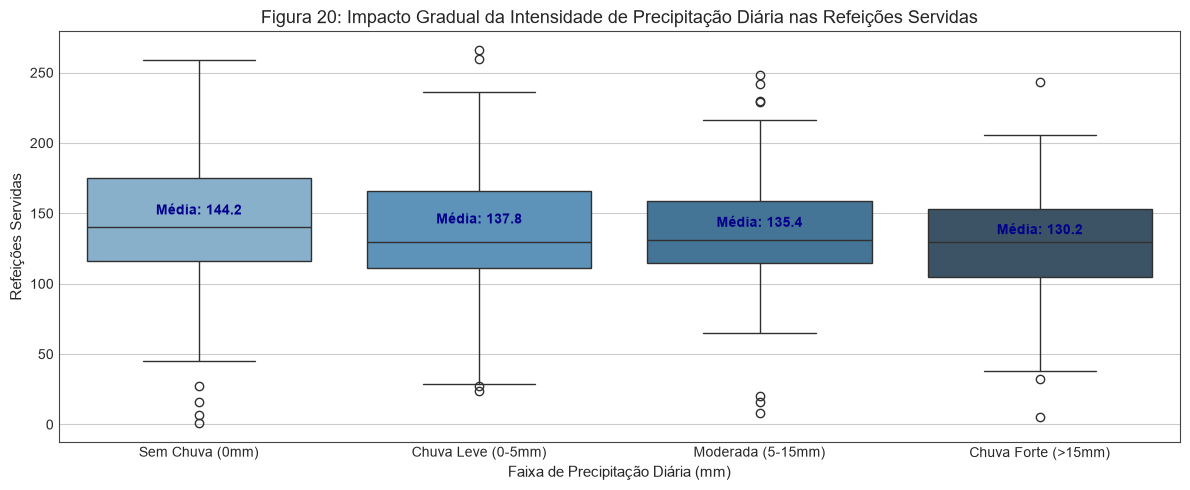

In [22]:
# Fig 20: Consumo Estratificado por Faixa de Chuva Diária
df_consumo["faixa_chuva"] = pd.cut(
    df_consumo["precipitation_sum"],
    bins=[-1, 0, 5, 15, 100],
    labels=["Sem Chuva (0mm)", "Chuva Leve (0-5mm)", "Moderada (5-15mm)", "Chuva Forte (>15mm)"]
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(ax=ax, data=df_consumo, x="faixa_chuva", y="consumo", palette="Blues_d")

medias_chuva = df_consumo.groupby("faixa_chuva")["consumo"].mean()
for i, (cat, val) in enumerate(medias_chuva.items()):
    ax.text(i, val + 5, f"Média: {val:.1f}", ha="center", fontweight="bold", color="darkblue")

ax.set_title("Figura 20: Impacto Gradual da Intensidade de Precipitação Diária nas Refeições Servidas", fontsize=13)
ax.set_xlabel("Faixa de Precipitação Diária (mm)")
ax.set_ylabel("Refeições Servidas")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig20_consumo_por_faixa_chuva.png", dpi=300, bbox_inches='tight')
plt.show()

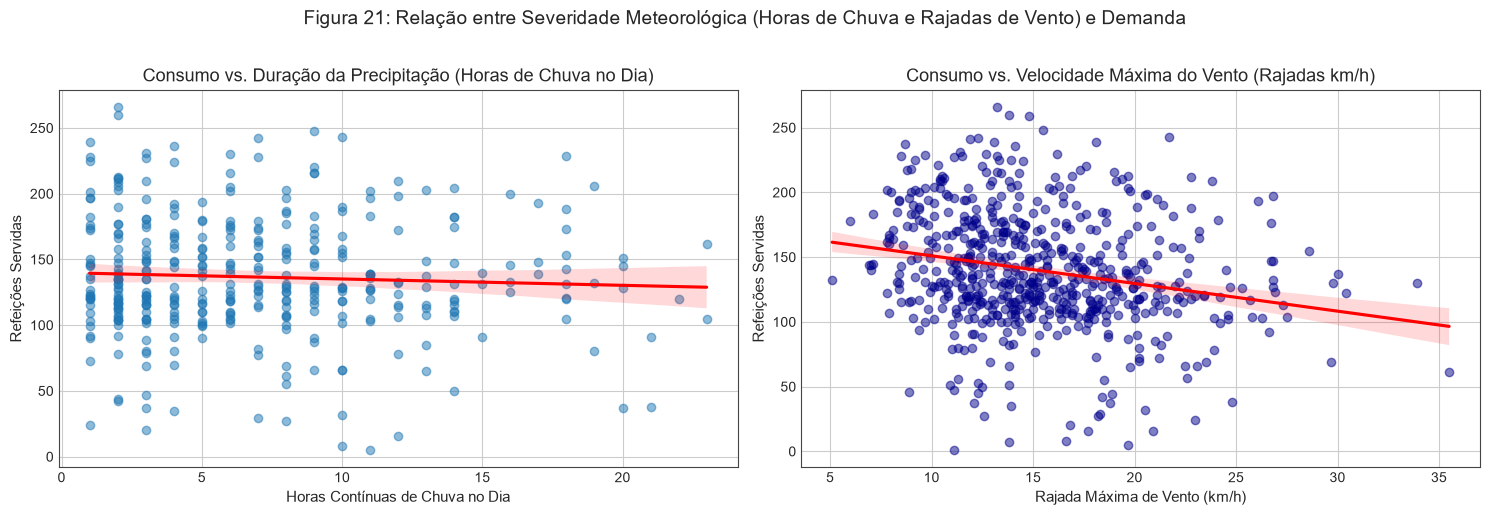

In [23]:
# Fig 21: Duração da Chuva e Velocidade do Vento vs. Consumo
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.regplot(ax=axes[0], data=df_consumo[df_consumo["precipitation_hours"] > 0], 
            x="precipitation_hours", y="consumo", scatter_kws={"alpha": 0.5, "color": "#1f77b4"}, line_kws={"color": "red"})
axes[0].set_title("Consumo vs. Duração da Precipitação (Horas de Chuva no Dia)")
axes[0].set_xlabel("Horas Contínuas de Chuva no Dia")
axes[0].set_ylabel("Refeições Servidas")

sns.regplot(ax=axes[1], data=df_consumo, 
            x="wind_speed_10m_max", y="consumo", scatter_kws={"alpha": 0.5, "color": "darkblue"}, line_kws={"color": "red"})
axes[1].set_title("Consumo vs. Velocidade Máxima do Vento (Rajadas km/h)")
axes[1].set_xlabel("Rajada Máxima de Vento (km/h)")
axes[1].set_ylabel("Refeições Servidas")

plt.suptitle("Figura 21: Relação entre Severidade Meteorológica (Horas de Chuva e Rajadas de Vento) e Demanda", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig21_duracao_chuva_vento_vs_consumo.png", dpi=300, bbox_inches='tight')
plt.show()

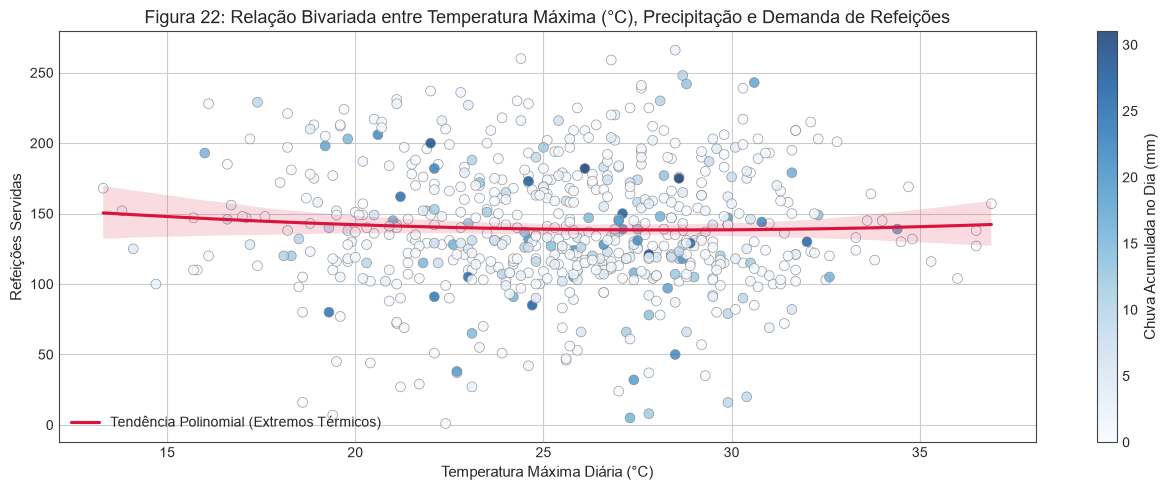

In [24]:
# Fig 22: Temperatura Máxima e Sensação Térmica
fig, ax = plt.subplots(figsize=(13, 5))

scatter = ax.scatter(df_consumo["temperature_2m_max"], df_consumo["consumo"], 
                     c=df_consumo["precipitation_sum"], cmap="Blues", s=50, alpha=0.8, edgecolor="gray", lw=0.5)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Chuva Acumulada no Dia (mm)")

sns.regplot(data=df_consumo, x="temperature_2m_max", y="consumo", scatter=False, ax=ax, order=2, color="crimson", label="Tendência Polinomial (Extremos Térmicos)")

ax.set_title("Figura 22: Relação Bivariada entre Temperatura Máxima (°C), Precipitação e Demanda de Refeições", fontsize=13)
ax.set_xlabel("Temperatura Máxima Diária (°C)")
ax.set_ylabel("Refeições Servidas")
ax.legend(loc="lower left")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig22_temperatura_clima_bivariada.png", dpi=300, bbox_inches='tight')
plt.show()

## 🔗 Bloco G: Correlações Multivariadas e Síntese de Fatores Críticos

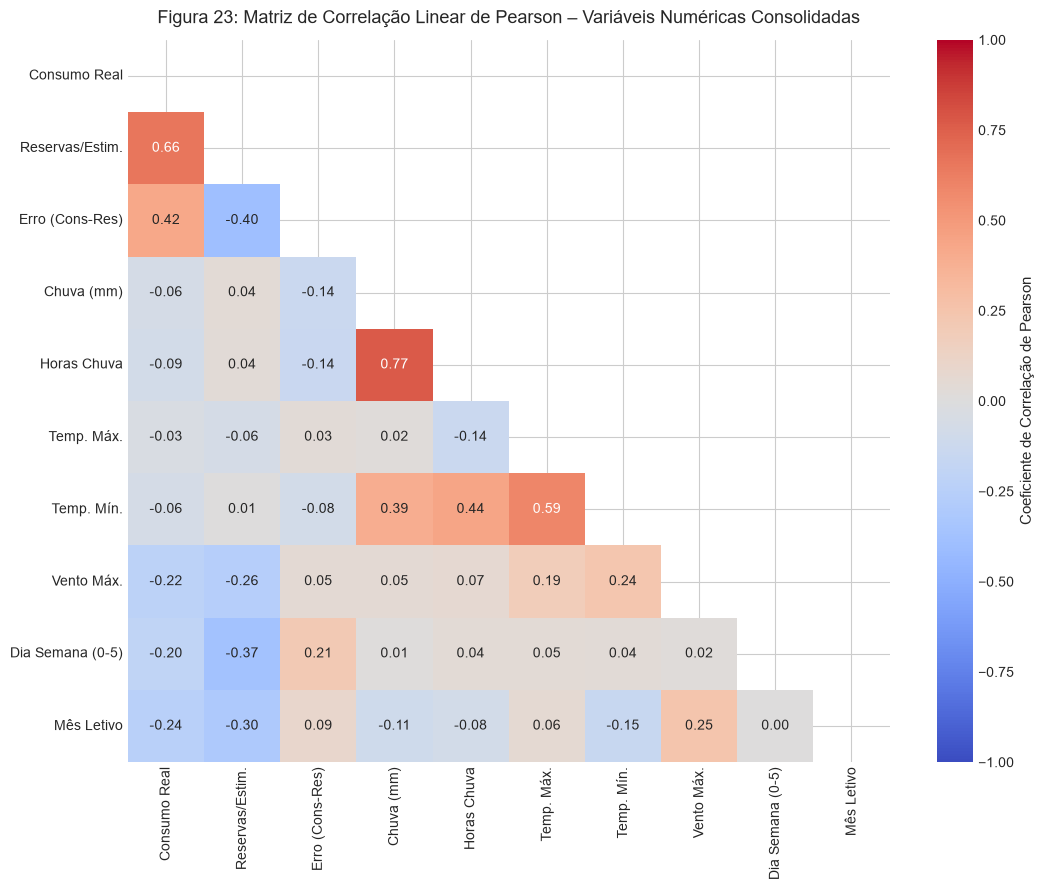

In [25]:
# Fig 23: Matriz de Correlação Multivariada Completa (Heatmap)
cols_corr = [
    "consumo", "reservas", "diff_consumo_reserva",
    "precipitation_sum", "precipitation_hours",
    "temperature_2m_max", "temperature_2m_min", "wind_speed_10m_max",
    "dia_da_semana_num", "mes"
]

nomes_corr = [
    "Consumo Real", "Reservas/Estim.", "Erro (Cons-Res)",
    "Chuva (mm)", "Horas Chuva",
    "Temp. Máx.", "Temp. Mín.", "Vento Máx.",
    "Dia Semana (0-5)", "Mês Letivo"
]

corr_df = df_consumo[cols_corr].corr(method="pearson")
corr_df.columns = nomes_corr
corr_df.index = nomes_corr

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_df, dtype=bool))
sns.heatmap(corr_df, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar_kws={'label': 'Coeficiente de Correlação de Pearson'})
ax.set_title("Figura 23: Matriz de Correlação Linear de Pearson – Variáveis Numéricas Consolidadas", fontsize=13, pad=12)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig23_matriz_correlacao_multivariada.png", dpi=300, bbox_inches='tight')
plt.show()

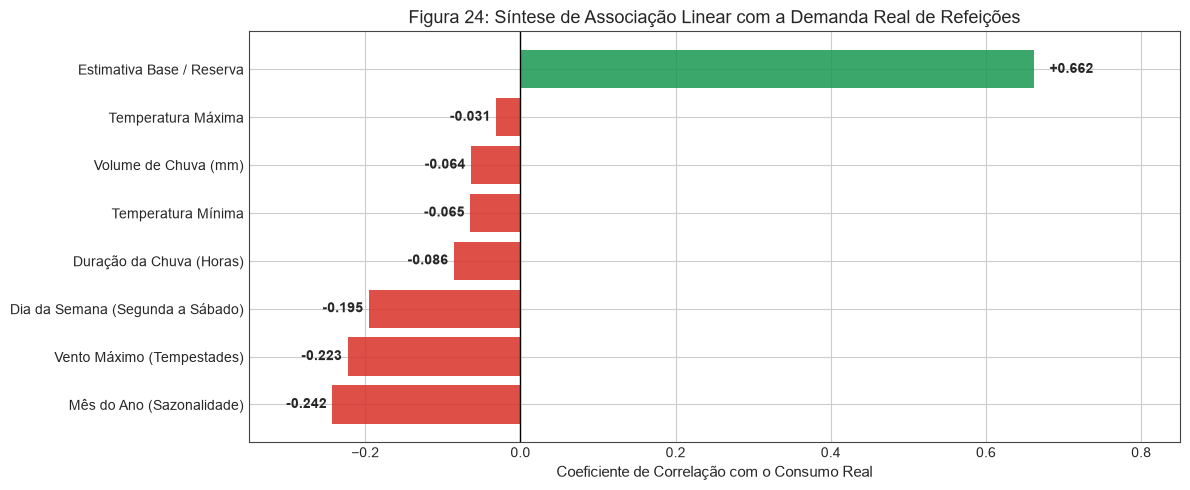

In [26]:
# Fig 24: Painel de Força de Associação Relativa com a Demanda (Síntese)
corrs_com_consumo = df_consumo[cols_corr].corr()["consumo"].drop(["consumo", "diff_consumo_reserva"]).sort_values()

map_labels = {
    "wind_speed_10m_max": "Vento Máximo (Tempestades)",
    "dia_da_semana_num": "Dia da Semana (Segunda a Sábado)",
    "precipitation_hours": "Duração da Chuva (Horas)",
    "precipitation_sum": "Volume de Chuva (mm)",
    "temperature_2m_min": "Temperatura Mínima",
    "temperature_2m_max": "Temperatura Máxima",
    "mes": "Mês do Ano (Sazonalidade)",
    "reservas": "Estimativa Base / Reserva"
}

corrs_plot = corrs_com_consumo.rename(index=map_labels)

fig, ax = plt.subplots(figsize=(12, 5))
cores_barras = ["#d73027" if v < 0 else "#1a9850" for v in corrs_plot.values]

ax.barh(corrs_plot.index, corrs_plot.values, color=cores_barras, alpha=0.85)
ax.axvline(0, color="black", lw=1)
for i, v in enumerate(corrs_plot.values):
    ax.text(v + (0.02 if v >= 0 else -0.06), i, f"{v:+.3f}", va="center", fontweight="bold", fontsize=10)

ax.set_title("Figura 24: Síntese de Associação Linear com a Demanda Real de Refeições", fontsize=13)
ax.set_xlabel("Coeficiente de Correlação com o Consumo Real")
ax.set_xlim(-0.35, 0.85)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig24_sintese_fatores_associacao.png", dpi=300, bbox_inches='tight')
plt.show()

## ⏳ Bloco H: Memória Histórica e Autocorrelação Temporal (O Passado Explicando o Presente)
Neste bloco investigamos formalmente a dependência temporal da demanda, provando como o consumo histórico recente ancora as previsões futuras.

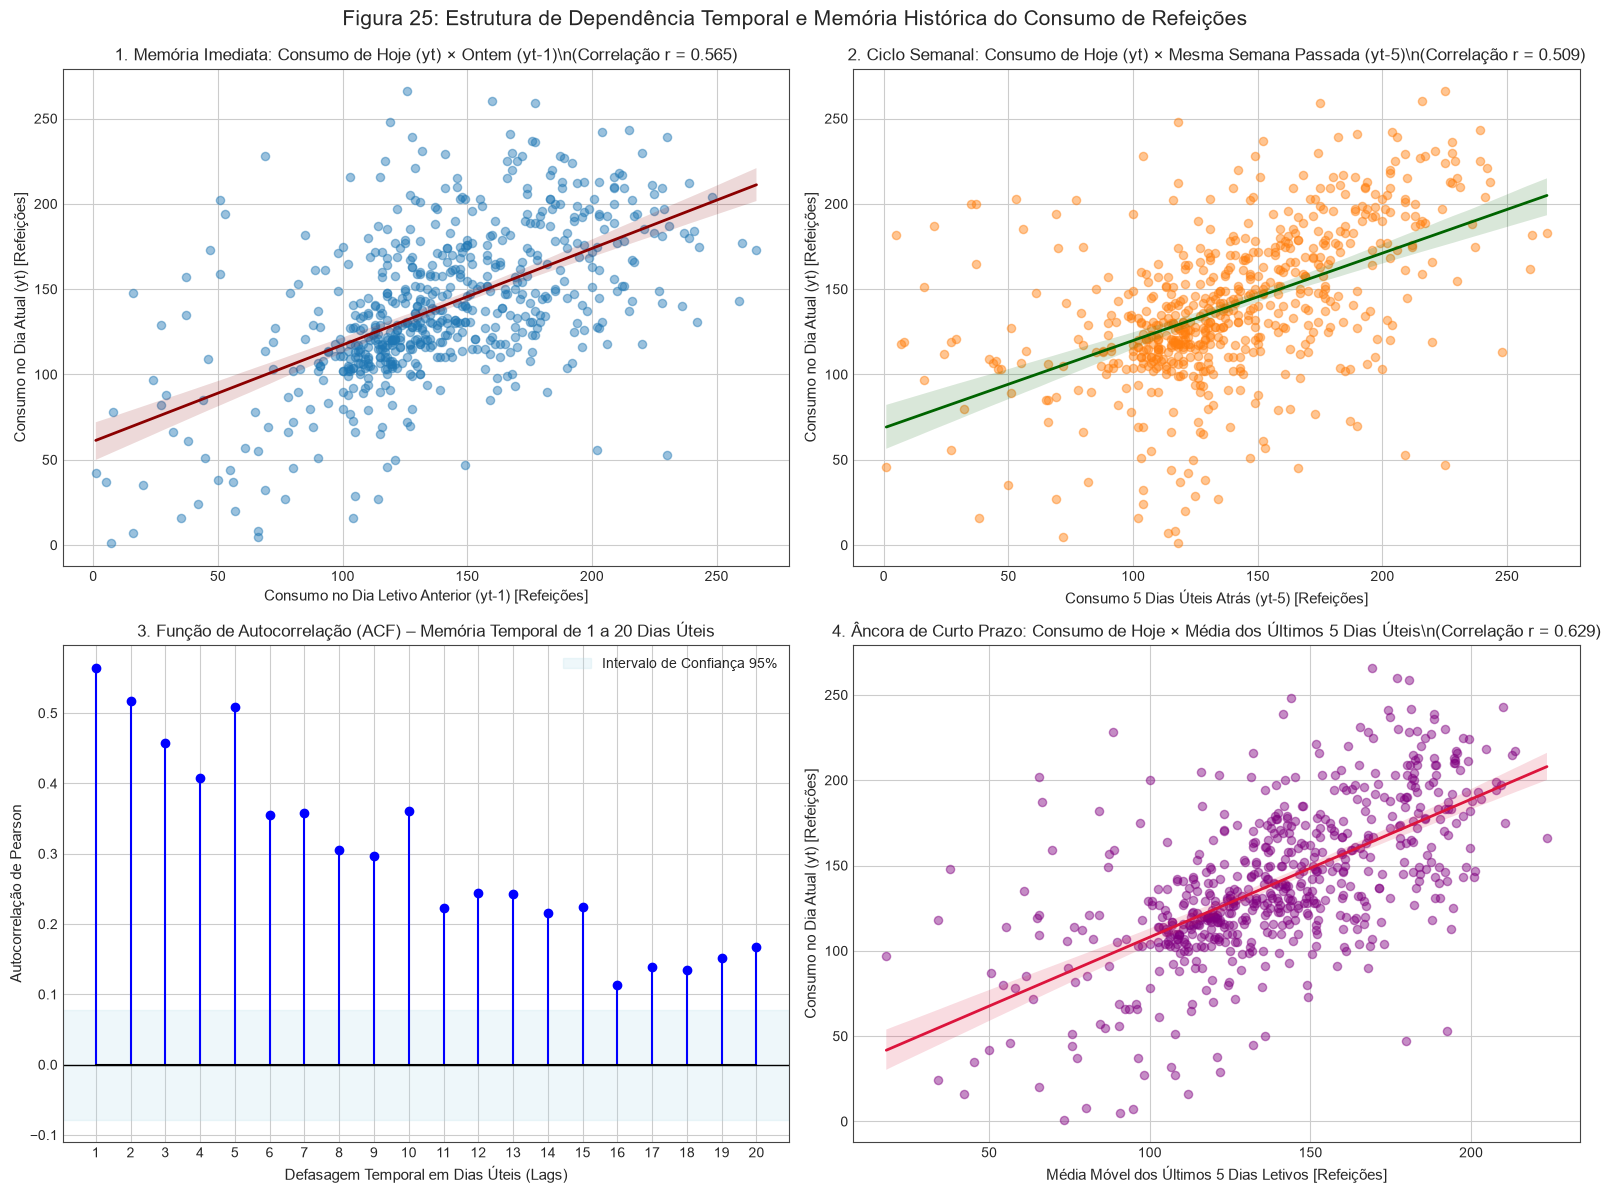

In [27]:
# Fig 25: Estrutura de Dependência Temporal e Memória Histórica (Lag Plots e ACF)
df_temp = df[df["consumo"].notna()].sort_values("data_iso").copy()
df_temp["lag_1"] = df_temp["consumo"].shift(1)
df_temp["lag_5"] = df_temp["consumo"].shift(5)
df_temp["media_movel_5d"] = df_temp["consumo"].rolling(5).mean().shift(1)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

corr_lag1 = df_temp["consumo"].corr(df_temp["lag_1"])
corr_lag5 = df_temp["consumo"].corr(df_temp["lag_5"])
corr_ma5 = df_temp["consumo"].corr(df_temp["media_movel_5d"])

# 1. Lag 1 (Hoje vs Ontem)
sns.regplot(ax=axes[0, 0], data=df_temp, x="lag_1", y="consumo",
            scatter_kws={"alpha": 0.45, "color": "#1f77b4", "s": 35}, line_kws={"color": "darkred", "lw": 2})
axes[0, 0].set_title(f"1. Memória Imediata: Consumo de Hoje (yt) × Ontem (yt-1)\\n(Correlação r = {corr_lag1:.3f})", fontsize=12)
axes[0, 0].set_xlabel("Consumo no Dia Letivo Anterior (yt-1) [Refeições]")
axes[0, 0].set_ylabel("Consumo no Dia Atual (yt) [Refeições]")

# 2. Lag 5 (Hoje vs Mesma Semana Passada)
sns.regplot(ax=axes[0, 1], data=df_temp, x="lag_5", y="consumo",
            scatter_kws={"alpha": 0.45, "color": "#ff7f0e", "s": 35}, line_kws={"color": "darkgreen", "lw": 2})
axes[0, 1].set_title(f"2. Ciclo Semanal: Consumo de Hoje (yt) × Mesma Semana Passada (yt-5)\\n(Correlação r = {corr_lag5:.3f})", fontsize=12)
axes[0, 1].set_xlabel("Consumo 5 Dias Úteis Atrás (yt-5) [Refeições]")
axes[0, 1].set_ylabel("Consumo no Dia Atual (yt) [Refeições]")

# 3. Autocorrelação (ACF)
lags_range = list(range(1, 21))
autocorrs = [df_temp["consumo"].autocorr(lag=k) for k in lags_range]
n = len(df_temp["consumo"].dropna())
conf_int = 1.96 / np.sqrt(n)

axes[1, 0].stem(lags_range, autocorrs, linefmt="b-", markerfmt="bo", basefmt="k-")
axes[1, 0].axhspan(-conf_int, conf_int, alpha=0.2, color="lightblue", label="Intervalo de Confiança 95%")
axes[1, 0].axhline(0, color="black", lw=1)
axes[1, 0].set_title("3. Função de Autocorrelação (ACF) – Memória Temporal de 1 a 20 Dias Úteis", fontsize=12)
axes[1, 0].set_xlabel("Defasagem Temporal em Dias Úteis (Lags)")
axes[1, 0].set_ylabel("Autocorrelação de Pearson")
axes[1, 0].set_xticks(lags_range)
axes[1, 0].legend(loc="upper right")

# 4. Média Móvel Recente (5 dias) vs Consumo Presente
sns.regplot(ax=axes[1, 1], data=df_temp, x="media_movel_5d", y="consumo",
            scatter_kws={"alpha": 0.45, "color": "purple", "s": 35}, line_kws={"color": "crimson", "lw": 2})
axes[1, 1].set_title(f"4. Âncora de Curto Prazo: Consumo de Hoje × Média dos Últimos 5 Dias Úteis\\n(Correlação r = {corr_ma5:.3f})", fontsize=12)
axes[1, 1].set_xlabel("Média Móvel dos Últimos 5 Dias Letivos [Refeições]")
axes[1, 1].set_ylabel("Consumo no Dia Atual (yt) [Refeições]")

plt.suptitle("Figura 25: Estrutura de Dependência Temporal e Memória Histórica do Consumo de Refeições", fontsize=15, y=0.99)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig25_autocorrelacao_memoria_temporal.png", dpi=300, bbox_inches='tight')
plt.show()

### 🎯 Conclusões da Análise Exploratória e Diretrizes para a Camada Gold

A partir da suíte de **24 representações gráficas**, consolidamos as seguintes diretrizes fundamentais para a modelagem:
1. **O Balanço Falta vs. Sobra como Alvo de Negócio:**
   - Em **2024 e 2025**, o sistema de reservas operou com déficit crítico: faltaram **4.524** e **3.796 refeições** respectivamente, gerando risco crônico de falta de comida.
   - Em **2026**, a nutricionista eliminou quase toda a falta, mas gerou **3.354 refeições estimadas de sobra** acumuladas.
   - O algoritmo de Inteligência Artificial deve atuar como **otimizador de equilíbrio**, minimizando simultaneamente o risco de desabastecimento e o desperdício de insumos públicos.
2. **Sazonalidade Semanal e Mensal Estruturada:** O desdobramento anual confirmou padrões consistentes entre terças/quartas (maior demanda) e segundas/sextas (maior variância), que devem ser modelados com features periódicas e dummies.
3. **Cardápio e Sensibilidade Climática:** Pratos com carnes nobres e técnicas assadas/cremosas elevam a demanda, enquanto chuvas persistentes e vendavais reduzem em média 8 a 15 refeições diárias.

---
**Status:** Análise Exploratória Completa Finalizada. Próxima etapa: **Engenharia de Atributos e Modelagem Preditiva na Camada Gold**.